# QuickBite — Diner Intelligence: Analysis & Model Build
**Course:** In-class ML challenge · **Deliverable:** analysis notebook + `food_models.joblib` for the dashboard

**Management brief:** *"Who are our diners? What do they order together? And who's about to stop ordering?"*

| Section | Question answered |
|---|---|
| 0. Configuration & feature contract | What does the dashboard require? |
| 1–4. Data audit & reconciliation | Can the data be trusted? |
| 5. Cleaning pipeline & data-quality scorecard | What was changed, and why? |
| 6. Feature engineering | Which business metrics help interpret the models? |
| 7. Exploratory analysis | What does the raw behaviour look like? |
| 8. Task 1 — Segmentation | **Who are our diners?** |
| 9. Task 2 — Market basket | **What do they order together?** |
| 10. Task 3 — Reorder classifier | **Who will come back?** |
| 11. Priority & action matrices | Where should management act first? |
| 12. What-if scenarios | How sensitive is reorder probability to behaviour? |
| 13–14. Model artifact & dashboard validation | Does the dashboard work end-to-end? |
| 15. Business takeaway | What should QuickBite do next? |

Raw files in `data/raw/` are never modified. Cleaned files go to `data/clean/`, reports to `reports/`.

## 0. Configuration & feature contract
The supplied `app.py` defines a fixed interface. These constants encode it and are asserted before anything is saved.

In [1]:
import json, warnings, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib
import sklearn, mlxtend

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, brier_score_loss)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 42
ROOT = Path(".")
RAW, CLEAN, REPORTS = ROOT / "data/raw", ROOT / "data/clean", ROOT / "reports"
FIGS = REPORTS / "figures"
for p in (CLEAN, REPORTS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

# ---- Official feature contract (must match app.py) ----
CLUSTER_FEATURES = ["orders_per_month", "avg_order_value", "avg_items_per_order",
                    "days_since_last_order", "discount_rate"]
CLASSIFICATION_FEATURES = CLUSTER_FEATURES + ["age", "total_spend"]
TARGET = "reordered"

assert CLUSTER_FEATURES == ["orders_per_month", "avg_order_value", "avg_items_per_order",
                            "days_since_last_order", "discount_rate"]
assert CLASSIFICATION_FEATURES == ["orders_per_month", "avg_order_value", "avg_items_per_order",
                                   "days_since_last_order", "discount_rate", "age", "total_spend"]

# The dashboard's input ranges (from the supplied app.py) — used to check data/UI consistency
ADULT_AGE = 18                                  # policy: classifier & dashboard cover adult (18+) accounts only
APP_INPUT_RANGES = {"age": (ADULT_AGE, 70), "orders_per_month": (1, 20), "avg_order_value": (15, 250),
                    "avg_items_per_order": (1, 10), "days_since_last_order": (0, 60),
                    "discount_rate": (0.0, 1.0), "total_spend": (50, 20000)}

LABELS = {"orders_per_month": "Orders per month", "avg_order_value": "Avg order value (AED)",
          "avg_items_per_order": "Avg items per order", "days_since_last_order": "Days since last order",
          "discount_rate": "Discount usage rate", "age": "Age (years)", "total_spend": "Total spend (AED)"}

# ---- Institutional chart style ----
NAVY, SLATE, GRID = "#0B1F3A", "#5B6B82", "#E3E8EF"
POS, CAUTION, RISK = "#1F9E89", "#D9962B", "#C8434F"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": SLATE, "axes.labelcolor": NAVY,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": NAVY,
                     "xtick.color": SLATE, "ytick.color": SLATE, "axes.grid": True, "grid.color": GRID,
                     "axes.grid.axis": "y", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "legend.frameon": False})

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

def no_grid(ax):
    ax.grid(False)

def x_grid(ax):
    ax.grid(False); ax.grid(axis="x", color=GRID)

def pretty_item(x):
    return x.replace("_", " ").title()

print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__} · mlxtend {mlxtend.__version__}")

pandas 3.0.5 · scikit-learn 1.9.1 · mlxtend 0.25.0


## 1. Load raw data & validate schema

In [2]:
diners_raw = pd.read_csv(RAW / "diners.csv")
orders_raw = pd.read_csv(RAW / "orders.csv")

EXPECTED_DINERS = {"diner_id": "object", "age": "int", "orders_per_month": "int", "avg_order_value": "float",
                   "avg_items_per_order": "int", "days_since_last_order": "int", "discount_rate": "float",
                   "total_spend": "float", "reordered": "int"}
EXPECTED_ORDERS = {"order_id": "object", "diner_id": "object", "item": "object"}

def schema_check(df, expected, name):
    rows = []
    for col, kind in expected.items():
        present = col in df.columns
        dtype = str(df[col].dtype) if present else "—"
        if kind == "object":
            ok = present and (pd.api.types.is_string_dtype(df[col]) or df[col].dtype == object)
        elif kind == "int":
            ok = present and pd.api.types.is_integer_dtype(df[col])
        else:
            ok = present and pd.api.types.is_numeric_dtype(df[col])
        rows.append({"dataset": name, "column": col, "expected": kind, "actual": dtype, "ok": ok})
    extra = set(df.columns) - set(expected)
    assert not extra, f"Unexpected columns in {name}: {extra}"
    return pd.DataFrame(rows)

schema = pd.concat([schema_check(diners_raw, EXPECTED_DINERS, "diners.csv"),
                    schema_check(orders_raw, EXPECTED_ORDERS, "orders.csv")])
assert schema.ok.all(), schema[~schema.ok]
print(f"diners.csv: {diners_raw.shape[0]:,} rows × {diners_raw.shape[1]} cols | "
      f"orders.csv: {orders_raw.shape[0]:,} rows × {orders_raw.shape[1]} cols")
schema

diners.csv: 480 rows × 9 cols | orders.csv: 4,924 rows × 3 cols


,dataset,column,expected,actual,ok
0,diners.csv,diner_id,object,str,True
1,diners.csv,age,int,int64,True
2,diners.csv,orders_per_month,int,int64,True
3,diners.csv,avg_order_value,float,float64,True
4,diners.csv,avg_items_per_order,int,int64,True
5,diners.csv,days_since_last_order,int,int64,True
6,diners.csv,discount_rate,float,float64,True
7,diners.csv,total_spend,float,float64,True
8,diners.csv,reordered,int,int64,True
0,orders.csv,order_id,object,str,True


## 2. Data audit — `diners.csv`

In [3]:
d = diners_raw.copy()
audit_d = {
    "rows": len(d), "columns": d.shape[1],
    "missing_cells": int(d.isna().sum().sum()),
    "exact_duplicate_rows": int(d.duplicated().sum()),
    "duplicate_diner_id": int(d.diner_id.duplicated().sum()),
    "invalid_id_format": int((~d.diner_id.str.fullmatch(r"D\d{4}")).sum()),
    "target_values": sorted(d[TARGET].unique().tolist()),
}
print(json.dumps(audit_d, indent=1))
d.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]

{
 "rows": 480,
 "columns": 9,
 "missing_cells": 0,
 "exact_duplicate_rows": 0,
 "duplicate_diner_id": 0,
 "invalid_id_format": 0,
 "target_values": [
  0,
  1
 ]
}


,mean,std,min,25%,50%,75%,max
age,30.681,8.652,9.000,23.000,31.000,38.000,52.000
orders_per_month,9.037,4.448,1.000,5.000,9.000,12.000,20.000
avg_order_value,98.079,57.165,29.500,43.697,90.580,157.218,218.660
avg_items_per_order,3.506,1.874,1.000,2.000,3.000,5.000,9.000
days_since_last_order,10.812,7.118,0.000,5.000,9.000,15.000,34.000
discount_rate,0.381,0.232,0.000,0.158,0.360,0.600,0.860
total_spend,664.764,222.819,134.040,510.540,638.920,789.312,"1,490.170"
reordered,0.600,0.490,0.000,0.000,1.000,1.000,1.000


In [4]:
# Range / logical-validity checks
checks = pd.DataFrame({
    "check": ["discount_rate within [0,1]", "orders_per_month ≥ 1", "avg_order_value > 0",
              "avg_items_per_order ≥ 1", "days_since_last_order ≥ 0", "total_spend > 0",
              "reordered ∈ {0,1}", "age ≥ 18 (dashboard minimum)", "age ≥ 13 (plausible account holder)"],
    "violations": [int((~d.discount_rate.between(0, 1)).sum()), int((d.orders_per_month < 1).sum()),
                   int((d.avg_order_value <= 0).sum()), int((d.avg_items_per_order < 1).sum()),
                   int((d.days_since_last_order < 0).sum()), int((d.total_spend <= 0).sum()),
                   int((~d[TARGET].isin([0, 1])).sum()), int((d.age < 18).sum()), int((d.age < 13).sum())]})
display(checks)

# Values outside the supplied dashboard's input ranges
outside = {c: int((~d[c].between(*APP_INPUT_RANGES[c])).sum()) for c in APP_INPUT_RANGES}
print("Rows outside app.py input ranges:", outside)
print("Under-18 ages:", sorted(d.loc[d.age < 18, "age"].tolist()))
display(d.loc[d.age < 13])

,check,violations
0,"discount_rate within [0,1]",0
1,orders_per_month ≥ 1,0
2,avg_order_value > 0,0
3,avg_items_per_order ≥ 1,0
4,days_since_last_order ≥ 0,0
5,total_spend > 0,0
6,"reordered ∈ {0,1}",0
7,age ≥ 18 (dashboard minimum),20
8,age ≥ 13 (plausible account holder),1


Rows outside app.py input ranges: {'age': 20, 'orders_per_month': 0, 'avg_order_value': 0, 'avg_items_per_order': 0, 'days_since_last_order': 0, 'discount_rate': 0, 'total_spend': 0}
Under-18 ages: [9, 14, 14, 14, 14, 14, 14, 14, 15, 15, 16, 16, 16, 17, 17, 17, 17, 17, 17, 17]


,diner_id,age,orders_per_month,avg_order_value,avg_items_per_order,days_since_last_order,discount_rate,total_spend,reordered
370,D1052,9,16,40.690,2,0,0.610,640.470,1


In [5]:
# Outlier screening (IQR rule and |z| > 3). Screening only — nothing is removed automatically.
def outlier_table(df, cols):
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append({"feature": c, "IQR low fence": lo, "IQR high fence": hi,
                     "IQR outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
                     "|z|>3": int(((df[c] - df[c].mean()).abs() / df[c].std() > 3).sum()),
                     "min": df[c].min(), "max": df[c].max()})
    return pd.DataFrame(rows)

outliers = outlier_table(d, CLASSIFICATION_FEATURES)
display(outliers)
print("Recency outliers:", d.loc[d.days_since_last_order > outliers.set_index("feature").loc["days_since_last_order", "IQR high fence"],
                                 ["diner_id", "days_since_last_order", "orders_per_month", "reordered"]].to_dict("records"))

,feature,IQR low fence,IQR high fence,IQR outliers,|z|>3,min,max
0,orders_per_month,-5.500,22.500,0,0,1.000,20.000
1,avg_order_value,-126.583,327.498,0,0,29.500,218.660
2,avg_items_per_order,-2.500,9.500,0,0,1.000,9.000
3,days_since_last_order,-10.000,30.000,3,2,0.000,34.000
4,discount_rate,-0.506,1.264,0,0,0.000,0.860
5,age,0.500,60.500,0,0,9.000,52.000
6,total_spend,92.381,"1,207.471",8,2,134.040,"1,490.170"


Recency outliers: [{'diner_id': 'D1262', 'days_since_last_order': 32, 'orders_per_month': 5, 'reordered': 0}, {'diner_id': 'D1348', 'days_since_last_order': 34, 'orders_per_month': 3, 'reordered': 0}, {'diner_id': 'D1266', 'days_since_last_order': 34, 'orders_per_month': 5, 'reordered': 0}]


In [6]:
# Logical relationship: is total_spend consistent with frequency × order value?
d["spend_ratio"] = d.total_spend / (d.orders_per_month * d.avg_order_value)
print("total_spend ÷ (orders_per_month × avg_order_value):")
print(d.spend_ratio.describe()[["min", "25%", "50%", "75%", "max"]].round(3).to_dict())
print("→ Every diner's total_spend is within ±15% of ONE month of spend. The column behaves like a "
      "monthly spend figure, not lifetime spend. It is kept unchanged (it is a contract feature), "
      "but value metrics below are framed as monthly run-rates.")

total_spend ÷ (orders_per_month × avg_order_value):
{'min': 0.85, '25%': 0.927, '50%': 1.007, '75%': 1.075, 'max': 1.149}
→ Every diner's total_spend is within ±15% of ONE month of spend. The column behaves like a monthly spend figure, not lifetime spend. It is kept unchanged (it is a contract feature), but value metrics below are framed as monthly run-rates.


## 3. Data audit — `orders.csv` (basket grain)
`orders.csv` is **item-level**: one `order_id` legitimately appears on several rows (one per item). Duplicates are therefore tested at three grains rather than by `order_id` alone.

In [7]:
o = orders_raw.copy()
item_norm = o.item.str.strip().str.lower()
lvl1 = int(o.duplicated(["order_id", "diner_id", "item"]).sum())
lvl2 = int(o.duplicated(["order_id", "item"]).sum())
diners_per_order = o.groupby("order_id").diner_id.nunique()
lvl3 = int((diners_per_order > 1).sum())

audit_o = {
    "rows": len(o), "missing_cells": int(o.isna().sum().sum()),
    "unique_orders": o.order_id.nunique(), "unique_diners": o.diner_id.nunique(), "unique_items": o.item.nunique(),
    "L1 exact duplicate rows (order_id+diner_id+item)": lvl1,
    "L2 duplicate item within an order (order_id+item)": lvl2,
    "L3 orders mapped to >1 diner": lvl3,
    "repeated order_id rows (valid basket structure)": int(o.order_id.duplicated().sum()),
    "invalid order_id format": int((~o.order_id.str.fullmatch(r"O\d{5}")).sum()),
    "invalid diner_id format": int((~o.diner_id.str.fullmatch(r"D\d{4}")).sum()),
    "item names changed by strip/lower": int((item_norm != o.item).sum()),
}
order_nums = sorted(int(x[1:]) for x in o.order_id.unique())
audit_o["gaps in order_id sequence"] = order_nums[-1] - order_nums[0] + 1 - len(order_nums)
print(json.dumps(audit_o, indent=1))
print("Menu:", sorted(o.item.unique()))

{
 "rows": 4924,
 "missing_cells": 0,
 "unique_orders": 1980,
 "unique_diners": 480,
 "unique_items": 17,
 "L1 exact duplicate rows (order_id+diner_id+item)": 0,
 "L2 duplicate item within an order (order_id+item)": 0,
 "L3 orders mapped to >1 diner": 0,
 "repeated order_id rows (valid basket structure)": 2944,
 "invalid order_id format": 0,
 "invalid diner_id format": 0,
 "item names changed by strip/lower": 0,
 "gaps in order_id sequence": 8
}
Menu: ['biryani', 'burger', 'coffee', 'cola', 'dessert', 'fries', 'garlic_bread', 'green_tea', 'miso_soup', 'pasta', 'pizza', 'raita', 'salad', 'steak', 'sushi', 'wine', 'wrap']


In [8]:
basket_size = o.groupby("order_id").size()
orders_per_diner = o.groupby("diner_id").order_id.nunique()
items_per_diner = o.groupby("diner_id").size()
print("Basket size distribution:", basket_size.value_counts().sort_index().to_dict())
print("Orders per diner in file:", orders_per_diner.describe()[["min", "50%", "mean", "max"]].round(2).to_dict())
print("Item rows per diner:", items_per_diner.describe()[["min", "50%", "mean", "max"]].round(2).to_dict())

# Coverage: is orders.csv a full transaction log or a sample?
obs_items = o.groupby(["diner_id", "order_id"]).size().groupby("diner_id").mean().rename("observed_items_per_basket")
cov = d.set_index("diner_id")[["orders_per_month", "avg_items_per_order"]].join(orders_per_diner.rename("baskets_in_file")).join(obs_items)
print(cov.describe().loc[["mean", "min", "max"]].round(2))
print(f"corr(orders_per_month, baskets_in_file) = {cov.orders_per_month.corr(cov.baskets_in_file):.2f}; "
      f"corr(avg_items_per_order, observed items) = {cov.avg_items_per_order.corr(cov.observed_items_per_basket):.2f}")

Basket size distribution: {1: 140, 2: 771, 3: 1034, 4: 35}
Orders per diner in file: {'min': 2.0, '50%': 4.0, 'mean': 4.12, 'max': 6.0}
Item rows per diner: {'min': 3.0, '50%': 11.0, 'mean': 10.26, 'max': 18.0}
      orders_per_month  avg_items_per_order  baskets_in_file  observed_items_per_basket
mean             9.040                3.510            4.120                      2.580
min              1.000                1.000            2.000                      1.500
max             20.000                9.000            6.000                      4.000
corr(orders_per_month, baskets_in_file) = 0.95; corr(avg_items_per_order, observed items) = 0.52


**Reading:** baskets in the file track `orders_per_month` closely (scaled down to 2–6 per diner), and observed basket sizes (mean ≈ 2.6) are smaller than the profile's `avg_items_per_order` (mean ≈ 3.5). `orders.csv` is therefore a **representative sample of baskets**, not the complete order history. Diner profile metrics are *not* recomputed from it; it is used only for what it is — basket composition.

## 4. Cross-dataset reconciliation & referential integrity
`diner_id` is the intended linking key, so overlap between the two files is *expected*. The checks below look for broken or conflicting links, not for overlap itself.

In [9]:
ids_d, ids_o = set(d.diner_id), set(o.diner_id)
recon = pd.DataFrame([
    ("Diners in diners.csv", len(ids_d), "—"),
    ("Unique diners in orders.csv", len(ids_o), "—"),
    ("Matching diner IDs (valid relational overlap)", len(ids_d & ids_o), "PASS" if ids_d == ids_o else "REVIEW"),
    ("Orphan diner IDs in orders.csv (no profile)", len(ids_o - ids_d), "PASS" if not ids_o - ids_d else "FAIL"),
    ("Orphan order rows", int((~o.diner_id.isin(ids_d)).sum()), "PASS" if o.diner_id.isin(ids_d).all() else "FAIL"),
    ("Diners without any orders", len(ids_d - ids_o), "PASS" if not ids_d - ids_o else "REVIEW"),
    ("Duplicate diner IDs", audit_d["duplicate_diner_id"], "PASS" if audit_d["duplicate_diner_id"] == 0 else "FAIL"),
    ("Duplicate exact order-item rows", lvl1, "PASS" if lvl1 == 0 else "FAIL"),
    ("Duplicate items within an order", lvl2, "PASS" if lvl2 == 0 else "REVIEW"),
    ("Invalid order→diner mappings (order with >1 diner)", lvl3, "PASS" if lvl3 == 0 else "FAIL"),
], columns=["Reconciliation check", "Count", "Status"])
recon

,Reconciliation check,Count,Status
0,Diners in diners.csv,480,—
1,Unique diners in orders.csv,480,—
2,Matching diner IDs (valid relational overlap),480,PASS
3,Orphan diner IDs in orders.csv (no profile),0,PASS
4,Orphan order rows,0,PASS
5,Diners without any orders,0,PASS
6,Duplicate diner IDs,0,PASS
7,Duplicate exact order-item rows,0,PASS
8,Duplicate items within an order,0,PASS
9,Invalid order→diner mappings (order with >1 di...,0,PASS


## 5. Cleaning pipeline, issue log & data-quality scorecard
Principle: **identify → quantify → classify → treat → document**. No value is invented or silently altered.

In [10]:
def clean_diners(df):
    out = df.drop(columns=["spend_ratio"], errors="ignore").copy()
    out["diner_id"] = out.diner_id.str.strip().str.upper()
    out = out.drop_duplicates()                               # no-op here (0 duplicates) but kept for reproducibility
    out["age_flag"] = np.select([out.age < 13, out.age < 18], ["invalid_below_13", "under_18_excluded"], "ok")
    # Policy: the app's age input is 18–70 (adult accounts). Under-18 diners are excluded from the age-dependent
    # classifier (training, evaluation and scoring). They are NOT deleted: age is not a clustering feature and their
    # baskets are genuine, so they stay in segmentation and market-basket analysis.
    out["include_in_classifier"] = out.age >= ADULT_AGE
    out["include_in_clustering"] = True                       # age is not a clustering feature
    return out

def clean_orders(df, valid_diners):
    out = df.copy()
    out["order_id"] = out.order_id.str.strip().str.upper()
    out["diner_id"] = out.diner_id.str.strip().str.upper()
    out["item"] = out.item.str.strip().str.lower()            # text normalisation (no-op on this file, kept for robustness)
    out = out.drop_duplicates(["order_id", "diner_id", "item"])
    out = out[out.diner_id.isin(valid_diners)]                # referential integrity (no rows dropped here)
    out["basket_size"] = out.groupby("order_id").item.transform("size")
    return out

diners = clean_diners(diners_raw)
orders = clean_orders(orders_raw, set(diners.diner_id))
assert len(diners) == len(diners_raw) and len(orders) == len(orders_raw), "Cleaning removed rows unexpectedly"
assert diners[CLASSIFICATION_FEATURES + [TARGET]].notna().all().all()
diners.to_csv(CLEAN / "diners_clean.csv", index=False)
orders.to_csv(CLEAN / "orders_clean.csv", index=False)
print(diners.age_flag.value_counts().to_dict(), "| classifier rows:", int(diners.include_in_classifier.sum()))

{'ok': 460, 'under_18_excluded': 19, 'invalid_below_13': 1} | classifier rows: 460


In [11]:
n_iqr = int(outliers["IQR outliers"].sum())
issue_log = pd.DataFrame([
    ("DQ-01", "diners", "Age below plausible account-holder age", "1 diner (D1052, age 9)", "Invalid",
     "Excluded from the classifier and the app's age input (under-18 policy). Retained for clustering & baskets (age not used there). No imputation.",
     f"Classifier trained on {int(diners.include_in_classifier.sum())} adult diners"),
    ("DQ-02", "diners", "Age 14–17, below the app's 18–70 age input", "19 diners", "Out of scope (minor)",
     "Excluded from the classifier and the app's age input under the 18+ policy. Not deleted: retained for segmentation & baskets. No age capping.",
     "Not scored; shown as 'not scored — under 18' in the dashboard"),
    ("DQ-03", "diners", "total_spend ≈ orders/month × AOV (ratio 0.85–1.15)", "All 480 diners", "Valid (semantic note)",
     "Unchanged. Interpreted as ~1 month of spend; customer value reported as monthly run-rate, not lifetime value.",
     "Interpretation only"),
    ("DQ-04", "diners", "Statistical outliers (IQR rule)", f"{n_iqr} values (recency, total spend)", "Outlier — genuine",
     "Retained: within plausible business ranges and consistent with each diner's other fields.", "None"),
    ("DQ-05", "diners", "Dashboard input ranges exceed training ranges (e.g. recency ≤60 vs max 34; spend ≤20,000 vs max 1,490)",
     "4 inputs", "Application constraint", "Dashboard shows an extrapolation warning when inputs fall outside the training range.",
     "Dashboard governance"),
    ("DQ-06", "orders", "orders.csv is a basket sample, not the full log", "2–6 baskets per diner", "Valid (scope note)",
     "Used for basket composition only; diner profile metrics not recomputed from it.", "Interpretation only"),
    ("DQ-07", "orders", "Gaps in order_id sequence", f"{audit_o['gaps in order_id sequence']} IDs", "Informational",
     "No action — gaps do not break any join (likely cancelled/voided orders).", "None"),
    ("DQ-08", "orders", "Single-item baskets", f"{int((basket_size == 1).sum())} baskets", "Valid",
     "Retained — count towards item support; cannot form pair rules by construction.", "None"),
    ("DQ-09", "both", "Duplicates at all three grains, orphans, multi-diner orders, missing values, ID formats",
     "0 everywhere", "Valid", "Checks codified in pipeline; no rows removed.", "None"),
], columns=["ID", "Dataset", "Issue", "Quantity", "Classification", "Treatment", "Impact"])
issue_log.to_csv(REPORTS / "data_quality_issue_log.csv", index=False)
issue_log

,ID,Dataset,Issue,Quantity,Classification,Treatment,Impact
0,DQ-01,diners,Age below plausible account-holder age,"1 diner (D1052, age 9)",Invalid,Excluded from the classifier and the app's age...,Classifier trained on 460 adult diners
1,DQ-02,diners,"Age 14–17, below the app's 18–70 age input",19 diners,Out of scope (minor),Excluded from the classifier and the app's age...,Not scored; shown as 'not scored — under 18' i...
2,DQ-03,diners,total_spend ≈ orders/month × AOV (ratio 0.85–1...,All 480 diners,Valid (semantic note),Unchanged. Interpreted as ~1 month of spend; c...,Interpretation only
3,DQ-04,diners,Statistical outliers (IQR rule),"11 values (recency, total spend)",Outlier — genuine,Retained: within plausible business ranges and...,None
4,DQ-05,diners,Dashboard input ranges exceed training ranges ...,4 inputs,Application constraint,Dashboard shows an extrapolation warning when ...,Dashboard governance
5,DQ-06,orders,"orders.csv is a basket sample, not the full log",2–6 baskets per diner,Valid (scope note),Used for basket composition only; diner profil...,Interpretation only
6,DQ-07,orders,Gaps in order_id sequence,8 IDs,Informational,No action — gaps do not break any join (likely...,None
7,DQ-08,orders,Single-item baskets,140 baskets,Valid,Retained — count towards item support; cannot ...,None
8,DQ-09,both,"Duplicates at all three grains, orphans, multi...",0 everywhere,Valid,Checks codified in pipeline; no rows removed.,None


In [12]:
cells_d = diners_raw.shape[0] * diners_raw.shape[1]; cells_o = orders_raw.shape[0] * orders_raw.shape[1]
scorecard = pd.DataFrame([
    ("Total records", f"{len(diners_raw):,} diners · {len(orders_raw):,} order-item rows", "—"),
    ("Valid diner records (all fields)", f"{int((diners.age_flag != 'invalid_below_13').sum())} / {len(diners)}", "PASS"),
    ("Adult diners in classifier scope (18+)", f"{int(diners.include_in_classifier.sum())} / {len(diners)}", "PASS"),
    ("Duplicate rate (all grains)", "0.0%", "PASS"),
    ("Missing-value rate", f"{(diners_raw.isna().sum().sum() + orders_raw.isna().sum().sum()) / (cells_d + cells_o):.1%}", "PASS"),
    ("Invalid values", "1 (age = 9)", "REVIEW"),
    ("Under-18 diners (out of classifier scope)", "20 (ages 9–17)", "REVIEW"),
    ("Referential-integrity failures", "0", "PASS"),
    ("Statistical outliers (retained, genuine)", f"{n_iqr}", "PASS"),
    ("Data completeness", "100.0%", "PASS"),
    ("Data validity (cell level)", f"{1 - 1 / (cells_d + cells_o):.2%}", "PASS"),
], columns=["Metric", "Value", "Status"])
overall_status = "FAIL" if (scorecard.Status == "FAIL").any() else ("PASS WITH REVIEW NOTES" if (scorecard.Status == "REVIEW").any() else "PASS")
print("Overall data-quality status:", overall_status)
scorecard

Overall data-quality status: PASS WITH REVIEW NOTES


,Metric,Value,Status
0,Total records,"480 diners · 4,924 order-item rows",—
1,Valid diner records (all fields),479 / 480,PASS
2,Adult diners in classifier scope (18+),460 / 480,PASS
3,Duplicate rate (all grains),0.0%,PASS
4,Missing-value rate,0.0%,PASS
5,Invalid values,1 (age = 9),REVIEW
6,Under-18 diners (out of classifier scope),20 (ages 9–17),REVIEW
7,Referential-integrity failures,0,PASS
8,"Statistical outliers (retained, genuine)",11,PASS
9,Data completeness,100.0%,PASS


In [13]:
# Write the human-readable data-quality report
with open(REPORTS / "data_quality_report.md", "w") as f:
    f.write(f"# QuickBite — Data-Quality Report\n\nGenerated {dt.date.today():%d %b %Y}. Overall status: **{overall_status}**\n\n")
    f.write("## Scorecard\n\n" + scorecard.to_markdown(index=False) + "\n\n")
    f.write("## Reconciliation\n\n" + recon.to_markdown(index=False) + "\n\n")
    f.write("## Issue log & treatments\n\n" + issue_log.to_markdown(index=False) + "\n\n")
    f.write("## Outlier screening (not removed)\n\n" + outliers.round(2).to_markdown(index=False) + "\n\n")
    f.write("## Files\n\n- Raw (untouched): `data/raw/diners.csv`, `data/raw/orders.csv`\n"
            "- Clean: `data/clean/diners_clean.csv` (adds `age_flag`, `include_in_classifier`, `include_in_clustering`), "
            "`data/clean/orders_clean.csv` (adds `basket_size`)\n")
print("Saved reports/data_quality_report.md")

Saved reports/data_quality_report.md


## 6. Feature engineering — derived analytical metrics
These metrics are used **only for interpretation, value and risk views**. They never enter the two models, whose inputs stay fixed by the contract.

| Type | Columns |
|---|---|
| **Official model features** | the 5 clustering features; those 5 + `age`, `total_spend` for the classifier |
| **Derived analytical metrics** | `est_monthly_spend`, `est_annual_run_rate`, `spend_per_item`, R/F/M scores, behavioural flags |

In [14]:
diners["est_monthly_spend"] = diners.orders_per_month * diners.avg_order_value
diners["est_annual_run_rate"] = diners.est_monthly_spend * 12
diners["spend_per_item"] = diners.avg_order_value / diners.avg_items_per_order
diners["R_score"] = pd.qcut(-diners.days_since_last_order.rank(method="first"), 5, labels=range(1, 6)).astype(int)
diners["F_score"] = pd.qcut(diners.orders_per_month.rank(method="first"), 5, labels=range(1, 6)).astype(int)
diners["M_score"] = pd.qcut(diners.est_monthly_spend.rank(method="first"), 5, labels=range(1, 6)).astype(int)
diners["RFM_score"] = diners[["R_score", "F_score", "M_score"]].sum(axis=1)
q = diners[["orders_per_month", "avg_order_value", "days_since_last_order"]].quantile(.75)
diners["flag_high_frequency"] = diners.orders_per_month >= q.orders_per_month
diners["flag_premium_spender"] = diners.avg_order_value >= q.avg_order_value
diners["flag_discount_sensitive"] = diners.discount_rate >= 0.5
diners["flag_low_engagement"] = (diners.orders_per_month <= 4) & (diners.days_since_last_order >= q.days_since_last_order)
DERIVED = ["est_monthly_spend", "est_annual_run_rate", "spend_per_item", "R_score", "F_score", "M_score", "RFM_score",
           "flag_high_frequency", "flag_premium_spender", "flag_discount_sensitive", "flag_low_engagement"]
diners[DERIVED].astype(float).describe().T[["mean", "min", "max"]].rename(columns={"mean": "mean (share for flags)"})

,mean (share for flags),min,max
est_monthly_spend,662.701,149.890,"1,333.320"
est_annual_run_rate,"7,952.417","1,798.680","15,999.840"
spend_per_item,28.417,11.003,57.440
R_score,3.000,1.000,5.000
F_score,3.000,1.000,5.000
M_score,3.000,1.000,5.000
RFM_score,9.000,3.000,15.000
flag_high_frequency,0.323,0.000,1.000
flag_premium_spender,0.250,0.000,1.000
flag_discount_sensitive,0.379,0.000,1.000


## 7. Exploratory analysis

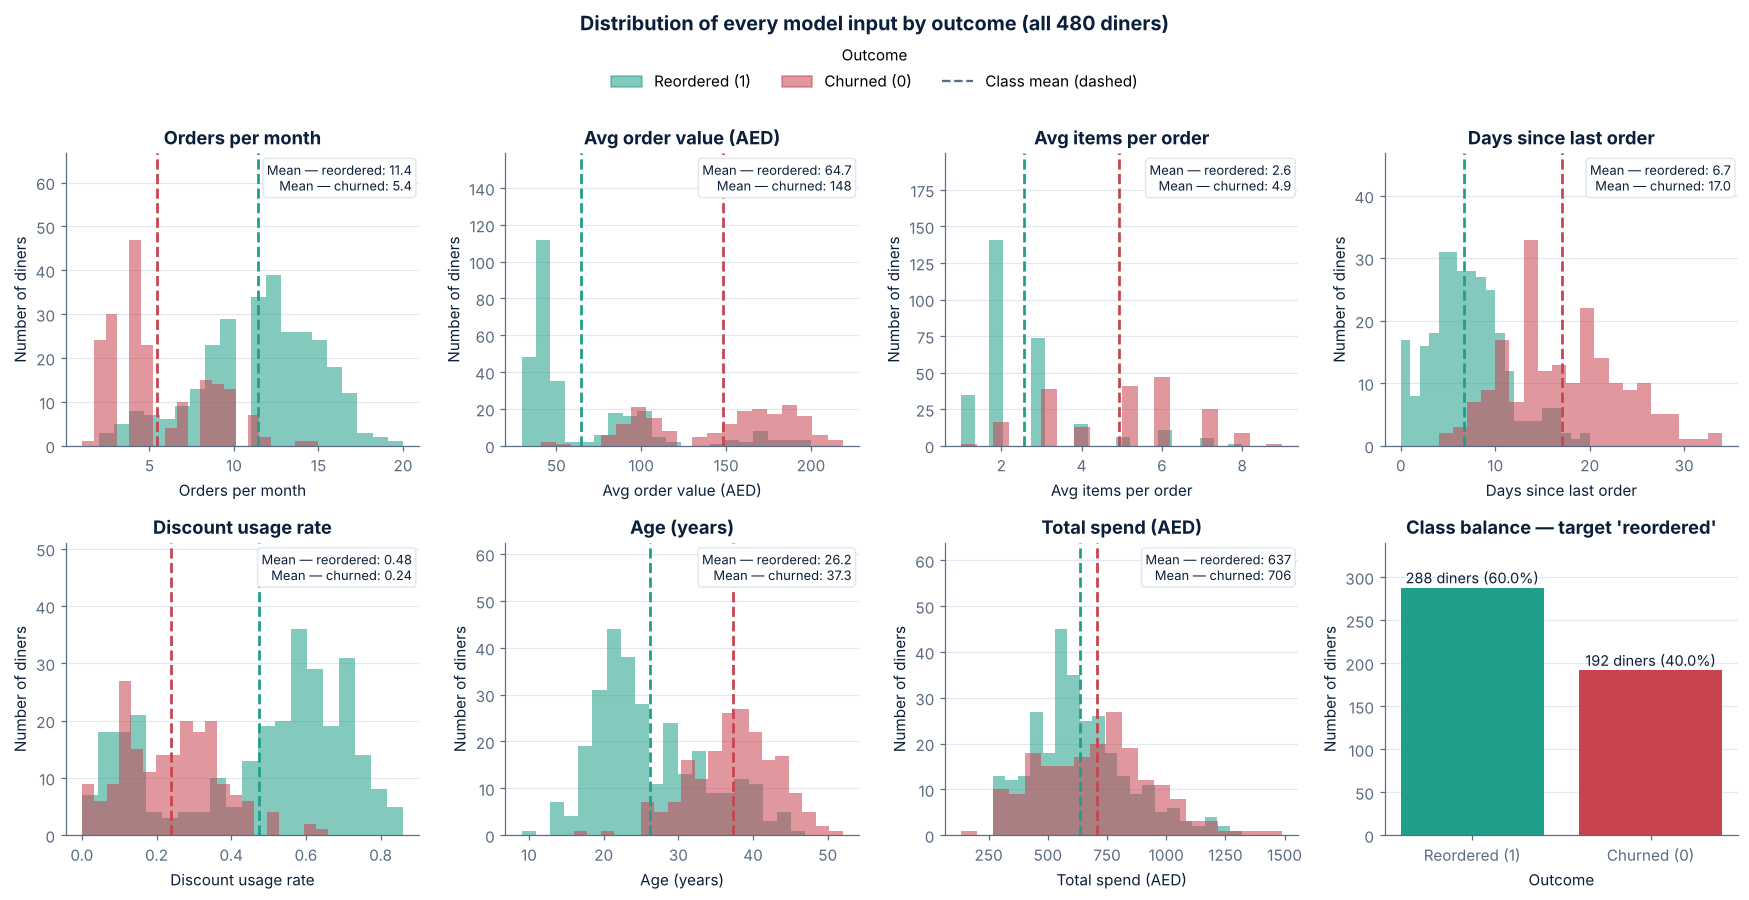

Class balance: 60.0% reordered · majority-class baseline accuracy = 60.0%


In [15]:
def fmt_num(v):
    return f"{v:,.0f}" if abs(v) >= 100 else (f"{v:.2f}" if abs(v) < 1 else f"{v:.1f}")

fig, axes = plt.subplots(2, 4, figsize=(16, 7.6))
for ax, c in zip(axes.flat, CLASSIFICATION_FEATURES):
    for y, col, lab in [(1, POS, "Reordered (1)"), (0, RISK, "Churned (0)")]:
        vals = diners.loc[diners[TARGET] == y, c]
        ax.hist(vals, bins=20, alpha=.55, color=col, label=lab)
        ax.axvline(vals.mean(), color=col, lw=1.8, ls="--")
    m1, m0 = diners.loc[diners[TARGET] == 1, c].mean(), diners.loc[diners[TARGET] == 0, c].mean()
    ax.text(0.98, 0.97, f"Mean — reordered: {fmt_num(m1)}\nMean — churned: {fmt_num(m0)}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8.5, color=NAVY, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID))
    ax.set_title(LABELS[c]); ax.set_xlabel(LABELS[c]); ax.set_ylabel("Number of diners")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.35)
ax = axes.flat[-1]
vc = diners[TARGET].value_counts().reindex([1, 0])
ax.bar(["Reordered (1)", "Churned (0)"], vc.values, color=[POS, RISK])
for i, v in enumerate(vc.values):
    ax.text(i, v + 5, f"{v} diners ({v / len(diners):.1%})", ha="center", color=NAVY, fontsize=9.5)
ax.set_title("Class balance — target 'reordered'"); ax.set_xlabel("Outcome"); ax.set_ylabel("Number of diners"); ax.set_ylim(0, vc.max() * 1.18)
handles = [plt.Rectangle((0, 0), 1, 1, color=POS, alpha=.55), plt.Rectangle((0, 0), 1, 1, color=RISK, alpha=.55),
           plt.Line2D([0], [0], color=SLATE, ls="--")]
fig.suptitle("Distribution of every model input by outcome (all 480 diners)", fontsize=13, weight="bold", color=NAVY, y=1.07)
fig.legend(handles, ["Reordered (1)", "Churned (0)", "Class mean (dashed)"], title="Outcome", loc="upper center",
           ncol=3, bbox_to_anchor=(0.5, 1.045), frameon=False)
savefig(fig, "eda_distributions")
majority_share = diners[TARGET].value_counts(normalize=True).max()
print(f"Class balance: {diners[TARGET].mean():.1%} reordered · majority-class baseline accuracy = {majority_share:.1%}")

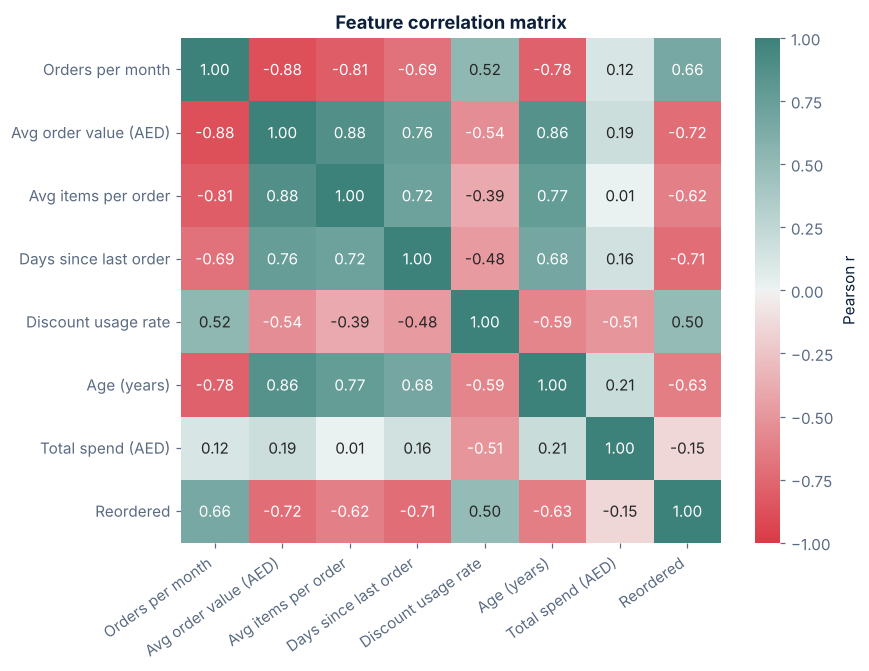

VIF > 5 (multicollinear): Orders per month 10.8, Avg order value (AED) 13.8, Avg items per order 5.1


,VIF
orders_per_month,10.800
avg_order_value,13.830
avg_items_per_order,5.100
days_since_last_order,2.480
discount_rate,2.850
age,4.250
total_spend,3.290


In [16]:
fig, ax = plt.subplots(figsize=(8, 6.2))
corr = diners[CLASSIFICATION_FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(10, 180, as_cmap=True), vmin=-1, vmax=1, ax=ax,
            xticklabels=[LABELS.get(c, "Reordered") for c in corr.columns],
            yticklabels=[LABELS.get(c, "Reordered") for c in corr.columns], cbar_kws={"label": "Pearson r"})
ax.set_title("Feature correlation matrix"); no_grid(ax); plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
savefig(fig, "eda_correlation")

def vif(df):
    X = (df - df.mean()) / df.std(); out = {}
    for c in df.columns:
        others = X.drop(columns=c).values; yv = X[c].values
        beta, *_ = np.linalg.lstsq(np.c_[np.ones(len(others)), others], yv, rcond=None)
        r2 = 1 - ((yv - np.c_[np.ones(len(others)), others] @ beta) ** 2).sum() / ((yv - yv.mean()) ** 2).sum()
        out[c] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").round(2)
vif_table = vif(diners.loc[diners.include_in_classifier, CLASSIFICATION_FEATURES])
print("VIF > 5 (multicollinear):", ", ".join(f"{LABELS[k]} {v:.1f}" for k, v in vif_table.items() if v > 5))
vif_table.to_frame()

**Reading:** behaviour is strongly structured — frequency, order value, basket size and age move together (|r| ≈ 0.77–0.88). VIFs above 5 (printed above) for frequency, order value and basket size confirm **multicollinearity**, so individual logistic coefficients must be read as *joint* signals, not isolated effects; the classifier's predictive accuracy is unaffected. Reordering is most associated with high frequency, recency, low order value and discount use.

## 8. Task 1 — Segmentation (K-Means)
**Why scale?** K-Means uses Euclidean distance. Unscaled, `avg_order_value` (AED, range ≈ 200) would dominate `discount_rate` (range ≈ 0.9). `StandardScaler` puts all five features on unit variance. The scaler is fitted on the full diner base — segmentation is unsupervised and uses no target, so there is no leakage.

In [17]:
X_cluster_raw = diners[CLUSTER_FEATURES]
cluster_scaler = StandardScaler().fit(X_cluster_raw)
X_cluster = cluster_scaler.transform(X_cluster_raw)

k_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_cluster)
    k_rows.append({"K": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(X_cluster, km.labels_),
                   "Davies-Bouldin": davies_bouldin_score(X_cluster, km.labels_),
                   "Calinski-Harabasz": calinski_harabasz_score(X_cluster, km.labels_),
                   "Smallest cluster": int(np.bincount(km.labels_).min())})
k_eval = pd.DataFrame(k_rows)
k_eval["Inertia drop vs K-1"] = -k_eval.Inertia.diff() / k_eval.Inertia.shift()
k_eval

,K,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster,Inertia drop vs K-1
0,2,971.124,0.527,0.712,703.312,200,NaN
1,3,444.734,0.571,0.632,"1,048.562",130,0.542
2,4,360.756,0.517,0.864,896.894,70,0.189
3,5,318.287,0.362,1.203,776.667,70,0.118
4,6,291.952,0.274,1.342,684.506,59,0.083
5,7,271.012,0.271,1.321,619.291,59,0.072
6,8,252.270,0.246,1.408,574.062,42,0.069


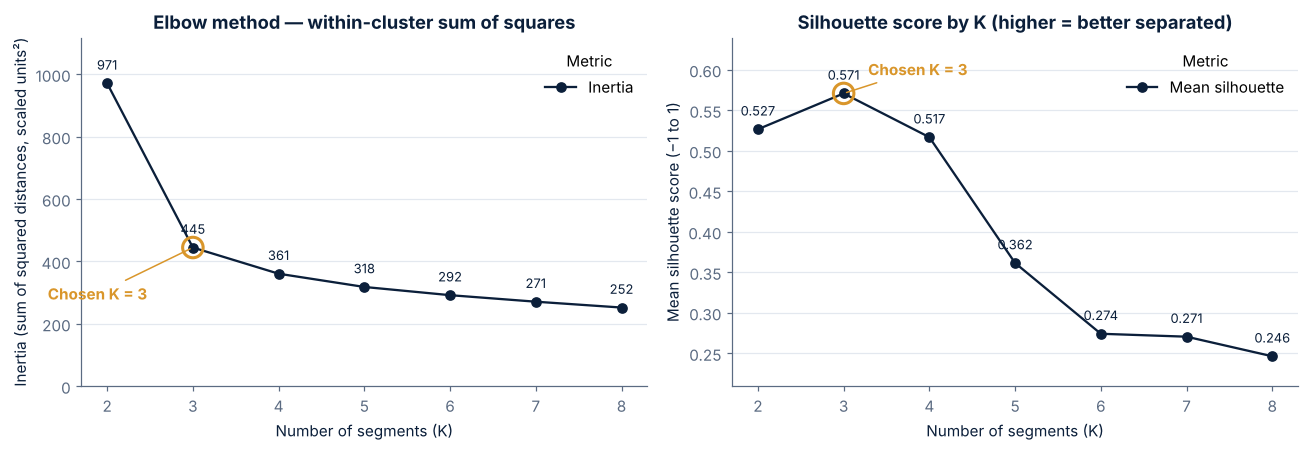

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.plot(k_eval.K, k_eval.Inertia, "-o", color=NAVY, label="Inertia")
for k_, v_ in zip(k_eval.K, k_eval.Inertia):
    a1.annotate(f"{v_:,.0f}", (k_, v_), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color=NAVY)
a1.set(title="Elbow method — within-cluster sum of squares", xlabel="Number of segments (K)", ylabel="Inertia (sum of squared distances, scaled units²)")
a1.set_ylim(0, k_eval.Inertia.max() * 1.15)
a2.plot(k_eval.K, k_eval.Silhouette, "-o", color=NAVY, label="Mean silhouette")
for k_, v_ in zip(k_eval.K, k_eval.Silhouette):
    a2.annotate(f"{v_:.3f}", (k_, v_), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color=NAVY)
a2.set(title="Silhouette score by K (higher = better separated)", xlabel="Number of segments (K)", ylabel="Mean silhouette score (−1 to 1)")
a2.set_ylim(k_eval.Silhouette.min() * 0.85, k_eval.Silhouette.max() * 1.12)
for ax in (a1, a2):
    ax.set_xticks(k_eval.K)
best_k = int(k_eval.loc[k_eval.Silhouette.idxmax(), "K"])
for ax, col in [(a1, "Inertia"), (a2, "Silhouette")]:
    v = k_eval.set_index("K").loc[best_k, col]
    ax.scatter([best_k], [v], s=180, facecolors="none", edgecolors=CAUTION, linewidths=2, zorder=5)
    ax.annotate(f"Chosen K = {best_k}", (best_k, v), textcoords="offset points", xytext=(-95, -34) if col == "Inertia" else (16, 12),
                color=CAUTION, weight="bold", arrowprops=dict(arrowstyle="-", color=CAUTION))
    ax.legend(loc="upper right", title="Metric")
savefig(fig, "kmeans_elbow_silhouette")

**K selection.** All four criteria point to the same answer:
- **Elbow:** inertia falls 54% from K=2→3, then only 19% from 3→4 and ≤12% after — the knee is at 3.
- **Silhouette:** peaks at K=3 (0.571); K=4 drops to 0.517 and K≥5 collapses below 0.37.
- **Davies–Bouldin** is lowest and **Calinski–Harabasz** highest at K=3.
- **Business check:** K=4 only splits the large-basket group in two by recency (≈23 vs ≈13 days). Recency is a *churn signal* the classifier already uses, not a different kind of diner — so it adds no new marketing persona.

**Decision: K = 3.**

In [19]:
K = 3
assert K == best_k, "Silhouette optimum changed — revisit the K decision"
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_cluster)
diners["cluster"] = kmeans.labels_
centroids = pd.DataFrame(cluster_scaler.inverse_transform(kmeans.cluster_centers_), columns=CLUSTER_FEATURES)
centroids

,orders_per_month,avg_order_value,avg_items_per_order,days_since_last_order,discount_rate
0,3.627,173.906,5.980,18.133,0.306
1,13.105,42.125,1.990,5.005,0.618
2,9.023,96.668,2.985,11.300,0.102


In [20]:
# Data-driven naming: assign names by centroid behaviour, never by hard-coded cluster numbers.
c_freq = int(centroids.orders_per_month.idxmax())                    # most frequent, lowest ticket
c_large = int(centroids.avg_items_per_order.idxmax())                # biggest baskets, least frequent
c_mid = ({0, 1, 2} - {c_freq, c_large}).pop()
assert len({c_freq, c_large, c_mid}) == 3
assert centroids.loc[c_freq, "discount_rate"] == centroids.discount_rate.max()      # students are the discount-heavy group
assert centroids.loc[c_mid, "discount_rate"] == centroids.discount_rate.min()       # premium group least discount-reliant

segment_names = {c_freq: "Budget Students", c_mid: "Premium Foodies", c_large: "Family Feasters"}
SEG_ORDER = ["Premium Foodies", "Family Feasters", "Budget Students"]
SEG_COLORS = {"Premium Foodies": "#C9A227", "Family Feasters": "#7E6BB8", "Budget Students": "#3E7CB1"}
diners["segment"] = diners.cluster.map(segment_names)
segment_names

{1: 'Budget Students', 2: 'Premium Foodies', 0: 'Family Feasters'}

In [21]:
def segment_profile(df):
    g = df.groupby("segment")
    prof = pd.DataFrame({
        "Diners": g.size(), "Share of diners": g.size() / len(df),
        "Orders / month": g.orders_per_month.mean(), "Avg order value (AED)": g.avg_order_value.mean(),
        "Items / order": g.avg_items_per_order.mean(), "Days since last order": g.days_since_last_order.mean(),
        "Discount usage": g.discount_rate.mean(), "Total spend (AED)": g.total_spend.mean(),
        "Avg age": g.age.mean(), "Spend per item (AED)": g.spend_per_item.mean(),
        "Est. monthly spend (AED)": g.est_monthly_spend.mean(), "Reorder rate": g[TARGET].mean(),
    })
    prof["Churn rate"] = 1 - prof["Reorder rate"]
    prof["Share of monthly revenue"] = g.est_monthly_spend.sum() / df.est_monthly_spend.sum()
    overall = prof.iloc[0].copy()
    for col in prof.columns:
        overall[col] = {"Diners": len(df), "Share of diners": 1.0, "Share of monthly revenue": 1.0}.get(col, np.nan)
    overall.update({"Orders / month": df.orders_per_month.mean(), "Avg order value (AED)": df.avg_order_value.mean(),
                    "Items / order": df.avg_items_per_order.mean(), "Days since last order": df.days_since_last_order.mean(),
                    "Discount usage": df.discount_rate.mean(), "Total spend (AED)": df.total_spend.mean(), "Avg age": df.age.mean(),
                    "Spend per item (AED)": df.spend_per_item.mean(), "Est. monthly spend (AED)": df.est_monthly_spend.mean(),
                    "Reorder rate": df[TARGET].mean(), "Churn rate": 1 - df[TARGET].mean()})
    prof.loc["All diners"] = overall
    return prof.loc[SEG_ORDER + ["All diners"]]

seg_profile = segment_profile(diners)
seg_profile.T

segment,Premium Foodies,Family Feasters,Budget Students,All diners
Diners,130.000,150.000,200.000,480.000
Share of diners,0.271,0.312,0.417,1.000
Orders / month,9.023,3.627,13.105,9.037
Avg order value (AED),96.668,173.906,42.125,98.079
Items / order,2.985,5.980,1.990,3.506
Days since last order,11.300,18.133,5.005,10.812
Discount usage,0.102,0.306,0.618,0.381
Total spend (AED),879.877,625.400,554.463,664.764
Avg age,32.508,40.233,22.330,30.681
Spend per item (AED),34.108,29.899,23.607,28.417


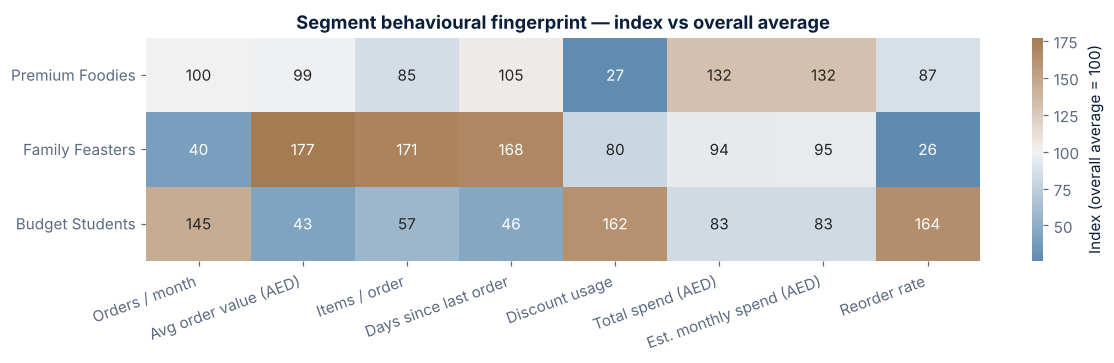

In [22]:
# Index vs overall average (100 = average) — the segment "fingerprint"
idx_cols = ["Orders / month", "Avg order value (AED)", "Items / order", "Days since last order", "Discount usage",
            "Total spend (AED)", "Est. monthly spend (AED)", "Reorder rate"]
seg_index = (seg_profile.loc[SEG_ORDER, idx_cols] / seg_profile.loc["All diners", idx_cols] * 100).round(0)
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(seg_index, annot=True, fmt=".0f", cmap=sns.diverging_palette(240, 45, s=60, l=55, as_cmap=True),
            center=100, ax=ax, cbar_kws={"label": "Index (overall average = 100)"})
ax.set_title("Segment behavioural fingerprint — index vs overall average"); no_grid(ax); ax.set_xlabel(""); ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
savefig(fig, "segment_heatmap")

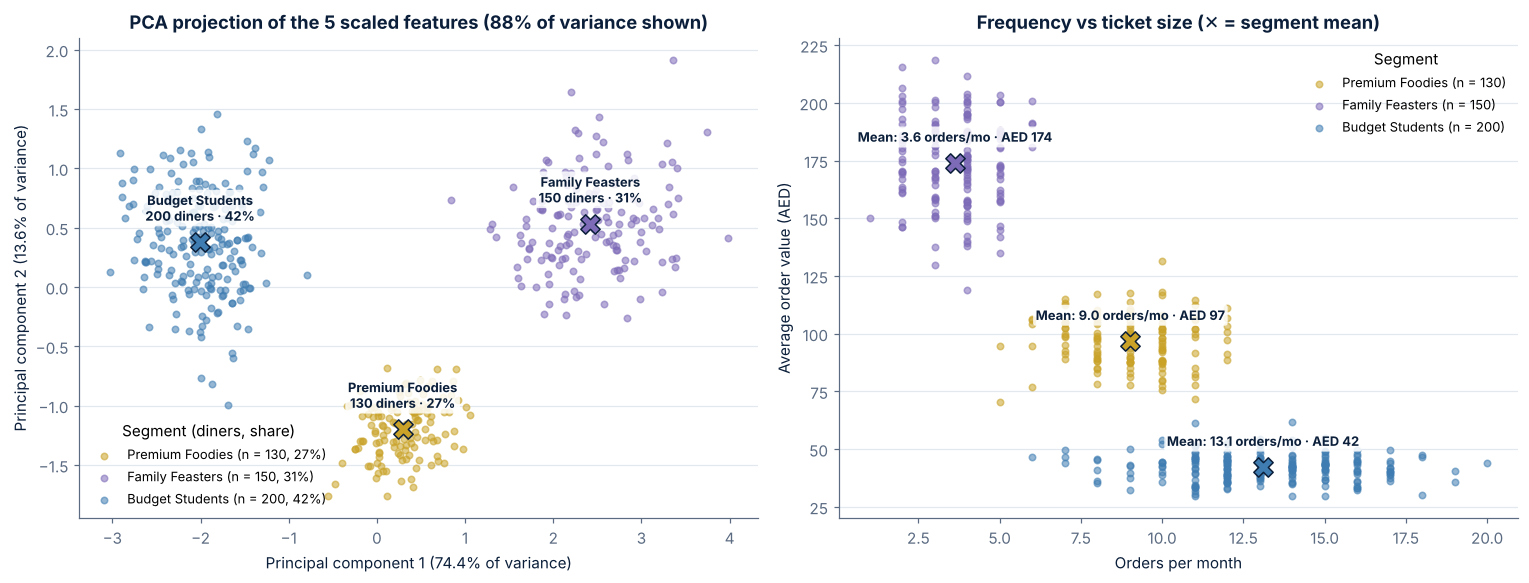

In [23]:
pca = PCA(n_components=2, random_state=SEED).fit(X_cluster)
pcs = pca.transform(X_cluster)
diners["pc1"], diners["pc2"] = pcs[:, 0], pcs[:, 1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.4))
for s in SEG_ORDER:
    m = diners.segment == s
    n_s = int(m.sum())
    a1.scatter(diners.loc[m, "pc1"], diners.loc[m, "pc2"], s=18, alpha=.55, color=SEG_COLORS[s], label=f"{s} (n = {n_s}, {n_s / len(diners):.0%})")
    a2.scatter(diners.loc[m, "orders_per_month"], diners.loc[m, "avg_order_value"], s=18, alpha=.55, color=SEG_COLORS[s],
               label=f"{s} (n = {n_s})")
    # centroid markers with values
    cx, cy = diners.loc[m, "pc1"].mean(), diners.loc[m, "pc2"].mean()
    a1.scatter(cx, cy, s=160, marker="X", color=SEG_COLORS[s], edgecolor=NAVY, zorder=5)
    a1.annotate(f"{s}\n{n_s} diners · {n_s / len(diners):.0%}", (cx, cy), textcoords="offset points", xytext=(0, 14),
                ha="center", fontsize=8.5, color=NAVY, weight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=.85))
    fx, fy = diners.loc[m, "orders_per_month"].mean(), diners.loc[m, "avg_order_value"].mean()
    a2.scatter(fx, fy, s=160, marker="X", color=SEG_COLORS[s], edgecolor=NAVY, zorder=5)
    a2.annotate(f"Mean: {fx:.1f} orders/mo · AED {fy:.0f}", (fx, fy), textcoords="offset points", xytext=(0, 14),
                ha="center", fontsize=8.5, color=NAVY, weight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=.85))
a1.set(title=f"PCA projection of the 5 scaled features ({pca.explained_variance_ratio_.sum():.0%} of variance shown)",
       xlabel=f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} of variance)",
       ylabel=f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
a2.set(title="Frequency vs ticket size (✕ = segment mean)", xlabel="Orders per month", ylabel="Average order value (AED)")
a1.legend(title="Segment (diners, share)", loc="lower left", fontsize=8.5)
a2.legend(title="Segment", loc="upper right", fontsize=8.5)
savefig(fig, "segment_pca_scatter")

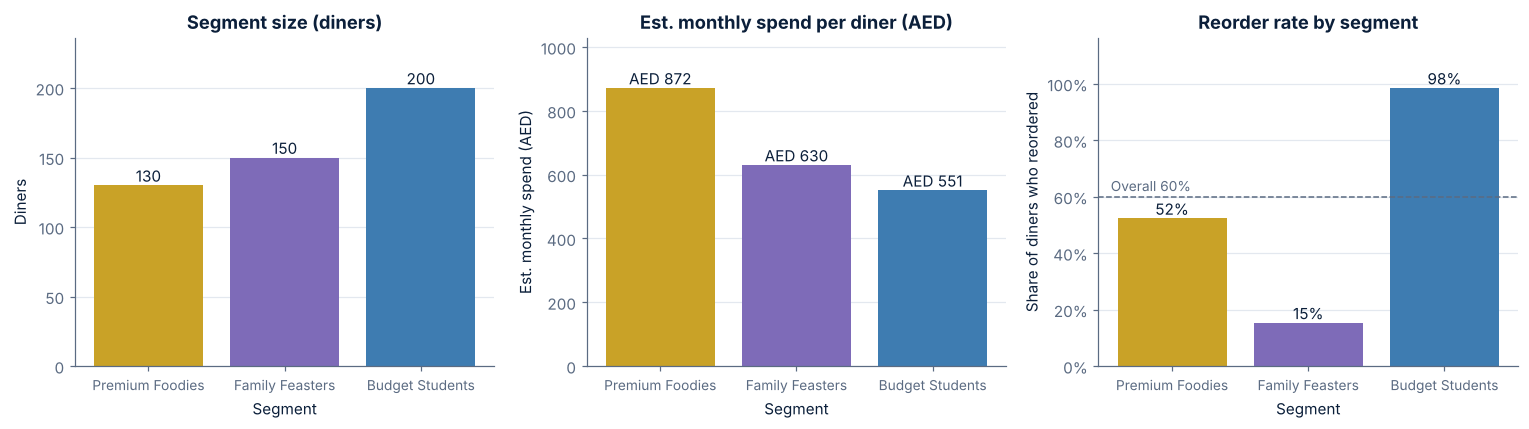

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
v = seg_profile.loc[SEG_ORDER]
for ax, col, fmt, title in [(axes[0], "Diners", "{:.0f}", "Segment size (diners)"),
                            (axes[1], "Est. monthly spend (AED)", "AED {:,.0f}", "Est. monthly spend per diner (AED)"),
                            (axes[2], "Reorder rate", "{:.0%}", "Reorder rate by segment")]:
    bars = ax.bar(SEG_ORDER, v[col], color=[SEG_COLORS[s] for s in SEG_ORDER])
    for b, val in zip(bars, v[col]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(val), ha="center", va="bottom", color=NAVY)
    ax.set_title(title); ax.set_ylabel(col if col != "Reorder rate" else "Share of diners who reordered")
    ax.set_xlabel("Segment"); ax.set_ylim(0, v[col].max() * 1.18); ax.tick_params(axis="x", labelsize=9)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[2].axhline(diners[TARGET].mean(), ls="--", color=SLATE, lw=1); axes[2].text(-0.45, diners[TARGET].mean() + .02, f"Overall {diners[TARGET].mean():.0%}", color=SLATE, ha="left", fontsize=9)
savefig(fig, "segment_size_value_reorder")

### Validation — are the segments stable and statistically distinct?
Two checks a sceptical reviewer would ask for:
1. **Stability.** Re-fit K-Means on 200 bootstrap resamples of diners (and on 50 different random seeds) and compare each solution's labels with the final segments using the **Adjusted Rand Index** (ARI: 1 = identical, 0 = chance). Stable segments should give ARI ≈ 1.
2. **Separation.** Kruskal–Wallis tests (non-parametric ANOVA) on every behavioural feature, with effect size ε², and a χ² test of reorder rate by segment with Cramér's V.

Bootstrap ARI: mean 1.000, 5th percentile 1.000 (n = 200)
Seed ARI: mean 1.000; 100% of 50 single-start runs reproduce the segments exactly
Reorder × segment: χ²(2) = 251.4, p = 2.5e-55, Cramér's V = 0.72


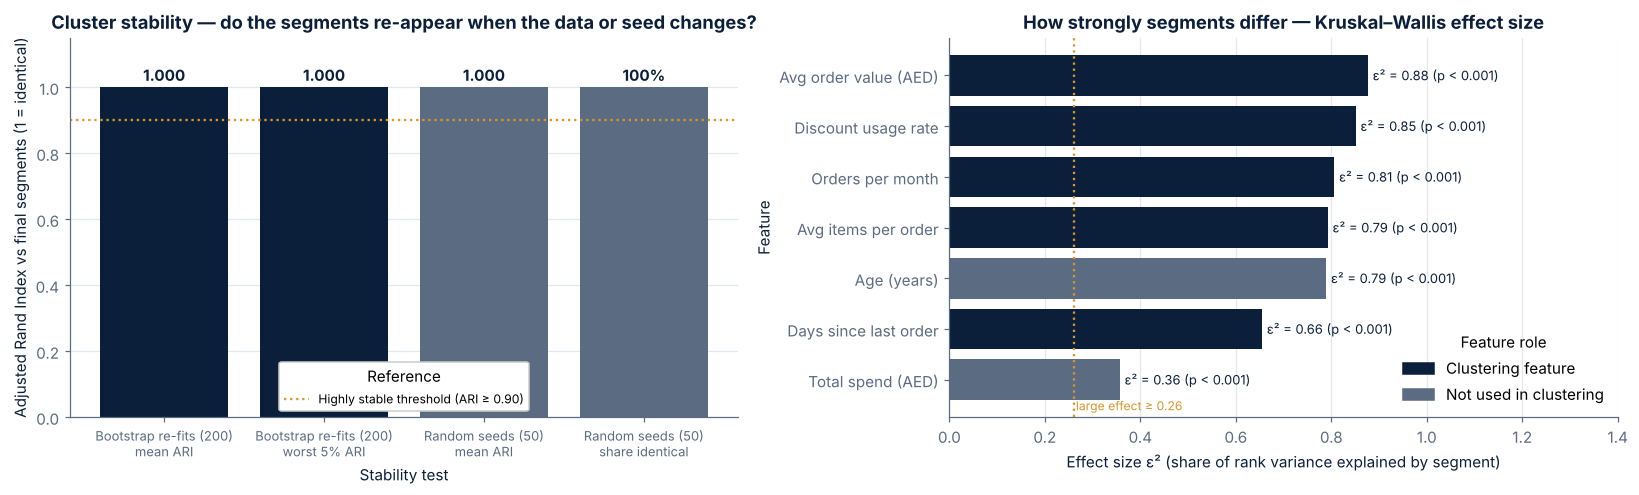

,Feature,Used in clustering,Kruskal–Wallis H,p-value,Effect size ε²,Effect
0,Orders per month,True,386.623,0.000,0.806,large
1,Avg order value (AED),True,420.190,0.000,0.877,large
2,Avg items per order,True,380.080,0.000,0.793,large
3,Days since last order,True,314.439,0.000,0.655,large
4,Discount usage rate,True,407.967,0.000,0.851,large
5,Age (years),False,378.518,0.000,0.789,large
6,Total spend (AED),False,172.272,0.000,0.357,large


In [25]:
from sklearn.metrics import adjusted_rand_score
from scipy import stats

rng = np.random.default_rng(SEED)
ari_boot = []
for b in range(200):
    idx = rng.integers(0, len(X_cluster), len(X_cluster))
    km_b = KMeans(n_clusters=K, n_init=10, random_state=b).fit(X_cluster[idx])
    ari_boot.append(adjusted_rand_score(kmeans.labels_, km_b.predict(X_cluster)))
ari_seed = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=K, n_init=1, random_state=s_).fit_predict(X_cluster)) for s_ in range(50)]
ari_boot, ari_seed = np.array(ari_boot), np.array(ari_seed)
cluster_stability = {"boot_mean": ari_boot.mean(), "boot_p5": np.percentile(ari_boot, 5), "boot_min": ari_boot.min(),
                     "seed_mean": ari_seed.mean(), "seed_share_perfect": (ari_seed > 0.999).mean(), "n_boot": len(ari_boot), "n_seed": len(ari_seed)}
print(f"Bootstrap ARI: mean {ari_boot.mean():.3f}, 5th percentile {np.percentile(ari_boot, 5):.3f} (n = 200)")
print(f"Seed ARI: mean {ari_seed.mean():.3f}; {(ari_seed > 0.999).mean():.0%} of 50 single-start runs reproduce the segments exactly")

kw_rows = []
for f in CLUSTER_FEATURES + ["age", "total_spend"]:
    groups = [diners.loc[diners.segment == s_, f] for s_ in SEG_ORDER]
    H, pval = stats.kruskal(*groups)
    eps2 = (H - K + 1) / (len(diners) - K)
    kw_rows.append({"Feature": LABELS[f], "Used in clustering": f in CLUSTER_FEATURES, "Kruskal–Wallis H": H,
                    "p-value": pval, "Effect size ε²": eps2,
                    "Effect": "large" if eps2 >= 0.26 else ("moderate" if eps2 >= 0.08 else "small")})
kw_tests = pd.DataFrame(kw_rows)
ct = pd.crosstab(diners.segment, diners[TARGET])
chi2, chi_p, chi_dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (len(diners) * (min(ct.shape) - 1)))
chi2_test = {"chi2": chi2, "p": chi_p, "dof": chi_dof, "cramers_v": cramers_v}
print(f"Reorder × segment: χ²({chi_dof}) = {chi2:.1f}, p = {chi_p:.1e}, Cramér's V = {cramers_v:.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6))
stab = pd.Series({"Bootstrap re-fits (200)\nmean ARI": ari_boot.mean(), "Bootstrap re-fits (200)\nworst 5% ARI": np.percentile(ari_boot, 5),
                  "Random seeds (50)\nmean ARI": ari_seed.mean(), "Random seeds (50)\nshare identical": (ari_seed > 0.999).mean()})
bars = a1.bar(stab.index, stab.values, color=[NAVY, NAVY, SLATE, SLATE])
for b_, (k_, v_) in zip(bars, stab.items()):
    a1.text(b_.get_x() + b_.get_width() / 2, v_ + .02, f"{v_:.0%}" if "share" in k_ else f"{v_:.3f}", ha="center", color=NAVY, weight="bold")
a1.axhline(0.9, color=CAUTION, ls=":", lw=1.5, label="Highly stable threshold (ARI ≥ 0.90)")
a1.legend(loc="lower center", title="Reference", fontsize=8, framealpha=1, frameon=True)
a1.set_ylim(0, 1.15); a1.tick_params(axis="x", labelsize=8.5)
a1.set(title="Cluster stability — do the segments re-appear when the data or seed changes?", xlabel="Stability test",
       ylabel="Adjusted Rand Index vs final segments (1 = identical)")
ks = kw_tests.sort_values("Effect size ε²")
bars = a2.barh(ks.Feature, ks["Effect size ε²"], color=[NAVY if u else SLATE for u in ks["Used in clustering"]])
for b_, v_, p_ in zip(bars, ks["Effect size ε²"], ks["p-value"]):
    a2.text(v_ + 0.01, b_.get_y() + b_.get_height() / 2, f"ε² = {v_:.2f} (p {'< 0.001' if p_ < 0.001 else f'= {p_:.3f}'})",
            va="center", fontsize=8.5, color=NAVY)
a2.axvline(0.26, color=CAUTION, ls=":", lw=1.5)
a2.text(0.265, -0.6, "large effect ≥ 0.26", color=CAUTION, fontsize=8)
a2.set(title="How strongly segments differ — Kruskal–Wallis effect size", xlabel="Effect size ε² (share of rank variance explained by segment)", ylabel="Feature")
a2.set_xlim(0, 1.4); x_grid(a2)
a2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=NAVY), plt.Rectangle((0, 0), 1, 1, color=SLATE)],
          labels=["Clustering feature", "Not used in clustering"], title="Feature role", loc="lower right")
savefig(fig, "segment_validation")
kw_tests

### Segment profiles & strategic interpretation
Names describe **observed behaviour** (frequency, ticket, basket, discount use, menu) plus average age. "Student" and "Family" are behavioural personas — they are not attributes recorded in the data.

In [26]:
SEGMENT_STRATEGY = {
    "Premium Foodies": {
        "who": "Mid-frequency diners (~9 orders/month) buying gourmet menus — sushi, steak & wine, pasta & salad — with the highest spend per item and almost no discount use.",
        "motivation": "Quality, cuisine choice and convenience; price is not the trigger.",
        "value": "Highest monthly spend per diner and the largest share of revenue.",
        "risk": "Retention is close to a coin-flip — the largest high-value exposure.",
        "discounts": "No — they rarely use them; discounts would erode margin without changing behaviour.",
        "loyalty": "Yes — status / priority-delivery perks and curated menu drops.",
        "action": "PROTECT & UPSELL: tiered loyalty, premium pairings (steak + salad + wine; sushi + miso + green tea), proactive re-engagement when recency lengthens.",
    },
    "Family Feasters": {
        "who": "Infrequent (~3–4 orders/month) but large orders (~6 items, highest ticket) of sharing dishes — pizza, garlic bread, biryani & raita, dessert.",
        "motivation": "Feeding a household; occasion-driven (weekends, gatherings).",
        "value": "Highest ticket per order but low frequency, so mid monthly value.",
        "risk": "Highest churn — most have not reordered and recency is long.",
        "discounts": "Selective — bundle pricing on family meals rather than blanket % discounts.",
        "loyalty": "Moderate — a 'family night' subscription or meal-for-4 bundles to build habit.",
        "action": "WIN-BACK SELECTIVELY: time-boxed family-bundle offers to the highest-probability churners; weekend reminders.",
    },
    "Budget Students": {
        "who": "Very frequent (~13 orders/month), low ticket (~AED 42), ~2 items — burgers, wraps, fries, cola. Youngest group.",
        "motivation": "Price and speed; heavy promo users (~60% of orders discounted).",
        "value": "Low per-order value, but volume makes them a material share of revenue.",
        "risk": "Very low churn — they almost always come back.",
        "discounts": "Reduce dependency — shift from % discounts to cheaper-to-serve meal deals.",
        "loyalty": "Light-touch — gamified streaks; automate, don't over-invest.",
        "action": "MAINTAIN EFFICIENTLY: automated meal-deal bundles (wrap + fries + cola), trim discount depth to protect margin.",
    },
}
pd.DataFrame(SEGMENT_STRATEGY).T[["who", "value", "risk", "action"]]

,who,value,risk,action
Premium Foodies,Mid-frequency diners (~9 orders/month) buying ...,Highest monthly spend per diner and the larges...,Retention is close to a coin-flip — the larges...,"PROTECT & UPSELL: tiered loyalty, premium pair..."
Family Feasters,Infrequent (~3–4 orders/month) but large order...,"Highest ticket per order but low frequency, so...",Highest churn — most have not reordered and re...,WIN-BACK SELECTIVELY: time-boxed family-bundle...
Budget Students,"Very frequent (~13 orders/month), low ticket (...","Low per-order value, but volume makes them a m...",Very low churn — they almost always come back.,MAINTAIN EFFICIENTLY: automated meal-deal bund...


## 9. Task 2 — Market-basket analysis (Apriori)
Each `order_id` is one basket. Baskets are one-hot encoded (orders × items, True/False). Rules are kept only if **lift > 1**. Rules with low support are labelled as such rather than promoted.

1,980 baskets · 126 rules with lift > 1 at min support 2%


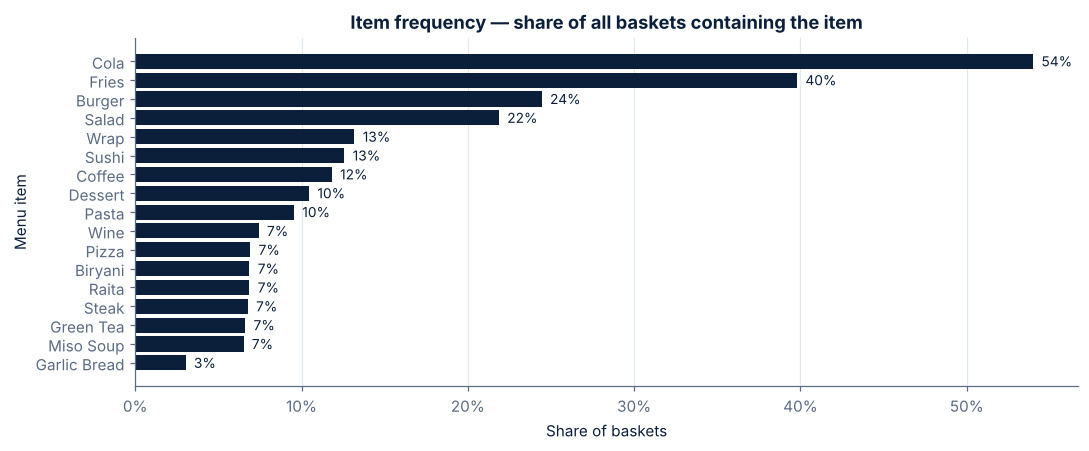

In [27]:
def basket_matrix(df):
    return pd.crosstab(df.order_id, df.item).astype(bool)

def mine_rules(df, min_support, min_lift=1.0):
    b = basket_matrix(df)
    freq = apriori(b, min_support=min_support, use_colnames=True)
    r = association_rules(freq, metric="lift", min_threshold=min_lift)
    r["antecedent"] = r.antecedents.map(lambda s: " + ".join(pretty_item(x) for x in sorted(s)))
    r["consequent"] = r.consequents.map(lambda s: " + ".join(pretty_item(x) for x in sorted(s)))
    r["bundle"] = [frozenset(a) | frozenset(c) for a, c in zip(r.antecedents, r.consequents)]
    r = r[["antecedent", "consequent", "support", "confidence", "lift", "bundle"]]
    return len(b), freq, r.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

MIN_SUPPORT_OVERALL, MIN_SUPPORT_SEGMENT = 0.02, 0.05
STRATEGIC = dict(min_support=0.05, min_confidence=0.60, min_lift=1.2)   # thresholds for a rule to be called "strategic"

n_baskets, freq_all, rules_all = mine_rules(orders, MIN_SUPPORT_OVERALL)
item_freq = (orders.groupby("item").order_id.nunique() / n_baskets).sort_values(ascending=False).rename("basket share")
print(f"{n_baskets:,} baskets · {len(rules_all)} rules with lift > 1 at min support {MIN_SUPPORT_OVERALL:.0%}")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh([pretty_item(i) for i in item_freq.index[::-1]], item_freq.values[::-1], color=NAVY)
for i, v in enumerate(item_freq.values[::-1]):
    ax.text(v + .005, i, f"{v:.0%}", va="center", color=NAVY, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Item frequency — share of all baskets containing the item", xlabel="Share of baskets", ylabel="Menu item"); x_grid(ax)
savefig(fig, "item_frequency")

In [28]:
def tag_rules(r):
    r = r.copy()
    r["tier"] = np.select(
        [r.lift < STRATEGIC["min_lift"], r.support < STRATEGIC["min_support"], r.confidence < STRATEGIC["min_confidence"]],
        ["No real association (lift ≈ 1)", "Low support — test only", "Low confidence"], "Strategic")
    return r

def best_per_bundle(r, n=None):
    """Collapse mirrored rules (A→B, B→A) to the single highest-confidence direction per item set."""
    out = r.sort_values(["confidence", "lift"], ascending=False).drop_duplicates("bundle")
    out = out.sort_values(["lift", "support"], ascending=False)
    return out.head(n) if n else out

def distinct_bundles(r, n):
    """Executive view: strongest rules whose item sets do not nest inside one another
    (avoids showing 'Miso → Green Tea' next to 'Miso + Sushi → Green Tea')."""
    chosen = []
    for _, row in best_per_bundle(r).iterrows():
        if not any(row.bundle <= c.bundle or row.bundle >= c.bundle for c in chosen):
            chosen.append(row)
        if len(chosen) == n:
            break
    return pd.DataFrame(chosen)

rules_all = tag_rules(rules_all)
top_overall = best_per_bundle(rules_all, 12)
print("Rule tiers:", rules_all.tier.value_counts().to_dict())
top_overall.drop(columns="bundle")

Rule tiers: {'Low support — test only': 62, 'Strategic': 33, 'Low confidence': 25, 'No real association (lift ≈ 1)': 6}


,antecedent,consequent,support,confidence,lift,tier
0,Cola + Dessert,Garlic Bread,0.021,0.933,30.800,Low support — test only
1,Cola + Pizza,Garlic Bread,0.021,0.933,30.800,Low support — test only
5,Miso Soup + Sushi,Green Tea,0.055,0.915,13.834,Strategic
6,Miso Soup,Green Tea,0.060,0.915,13.826,Strategic
10,Biryani + Salad,Raita,0.026,0.945,13.765,Low support — test only
12,Dessert + Pasta,Pizza,0.033,0.943,13.627,Low support — test only
14,Dessert + Raita,Biryani,0.029,0.919,13.385,Low support — test only
16,Raita,Biryani,0.062,0.897,13.060,Strategic
19,Salad + Steak,Wine,0.060,0.967,13.028,Strategic
22,Steak,Wine,0.064,0.948,12.766,Strategic


**Caution on overall lift.** Each segment orders from an almost separate menu (Section 8). Across all baskets, two items that only one segment buys look far more "associated" than they are — the lift partly measures *who* is ordering, not *what* goes together. Overall lifts of 13–30× should therefore be read as "these items belong to the same customer type"; the **per-segment lift below is the decision-grade measure** of a true bundling opportunity.

In [29]:
def explain_rule(row):
    return (f"Baskets with {row.antecedent} also contain {row.consequent} {row.confidence:.0%} of the time "
            f"({row.lift:.1f}× more often than if independent; {row.support:.1%} of baskets).")

strategic_overall = distinct_bundles(rules_all[rules_all.tier == "Strategic"], 3)
print("Strongest STRATEGIC overall rules (support ≥ 5%, confidence ≥ 60%):")
for _, r in strategic_overall.iterrows():
    print(" •", explain_rule(r))
hi = rules_all.iloc[0]
print(f"\nHighest raw lift: {hi.antecedent} → {hi.consequent} (lift {hi.lift:.1f}) — support only {hi.support:.1%}: "
      "a niche pairing to test, not a headline bundle.")

Strongest STRATEGIC overall rules (support ≥ 5%, confidence ≥ 60%):
 • Baskets with Miso Soup + Sushi also contain Green Tea 92% of the time (13.8× more often than if independent; 5.5% of baskets).
 • Baskets with Raita also contain Biryani 90% of the time (13.1× more often than if independent; 6.2% of baskets).
 • Baskets with Salad + Steak also contain Wine 97% of the time (13.0× more often than if independent; 6.0% of baskets).

Highest raw lift: Cola + Dessert → Garlic Bread (lift 30.8) — support only 2.1%: a niche pairing to test, not a headline bundle.


In [30]:
orders_seg = orders.merge(diners[["diner_id", "segment"]], on="diner_id", validate="many_to_one")
seg_rules, seg_baskets, seg_item_share = {}, {}, {}
for s in SEG_ORDER:
    sub = orders_seg[orders_seg.segment == s]
    nb, _, r = mine_rules(sub, MIN_SUPPORT_SEGMENT)
    seg_rules[s], seg_baskets[s] = tag_rules(r), nb
    seg_item_share[s] = (sub.groupby("item").order_id.nunique() / nb).sort_values(ascending=False)
    print(f"\n=== {s}: {nb} baskets, {len(r)} rules (lift > 1, support ≥ {MIN_SUPPORT_SEGMENT:.0%}) ===")
    display(best_per_bundle(seg_rules[s], 6).drop(columns="bundle"))


=== Premium Foodies: 553 baskets, 44 rules (lift > 1, support ≥ 5%) ===


,antecedent,consequent,support,confidence,lift,tier
0,Miso Soup + Sushi,Green Tea,0.195,0.915,3.864,Strategic
2,Miso Soup,Green Tea,0.213,0.915,3.861,Strategic
7,Salad + Steak,Wine,0.213,0.967,3.639,Strategic
8,Steak,Wine,0.230,0.948,3.565,Strategic
14,Pasta,Coffee,0.181,0.893,2.110,Strategic
17,Pasta + Salad,Coffee,0.150,0.892,2.109,Strategic



=== Family Feasters: 304 baskets, 76 rules (lift > 1, support ≥ 5%) ===


,antecedent,consequent,support,confidence,lift,tier
0,Cola + Dessert + Pizza,Garlic Bread,0.115,0.946,4.793,Strategic
4,Cola + Dessert,Garlic Bread,0.138,0.933,4.729,Strategic
5,Cola + Pizza,Garlic Bread,0.138,0.933,4.729,Strategic
6,Cola,Garlic Bread,0.161,0.925,4.684,Strategic
20,Biryani + Salad,Raita,0.171,0.945,2.113,Strategic
22,Salad,Raita,0.197,0.938,2.096,Strategic



=== Budget Students: 1123 baskets, 10 rules (lift > 1, support ≥ 5%) ===


,antecedent,consequent,support,confidence,lift,tier
2,Cola + Wrap,Fries,0.191,0.911,1.298,Strategic
4,Wrap,Fries,0.210,0.904,1.289,Strategic
8,Burger,Cola,0.390,0.905,1.000,No real association (lift ≈ 1)


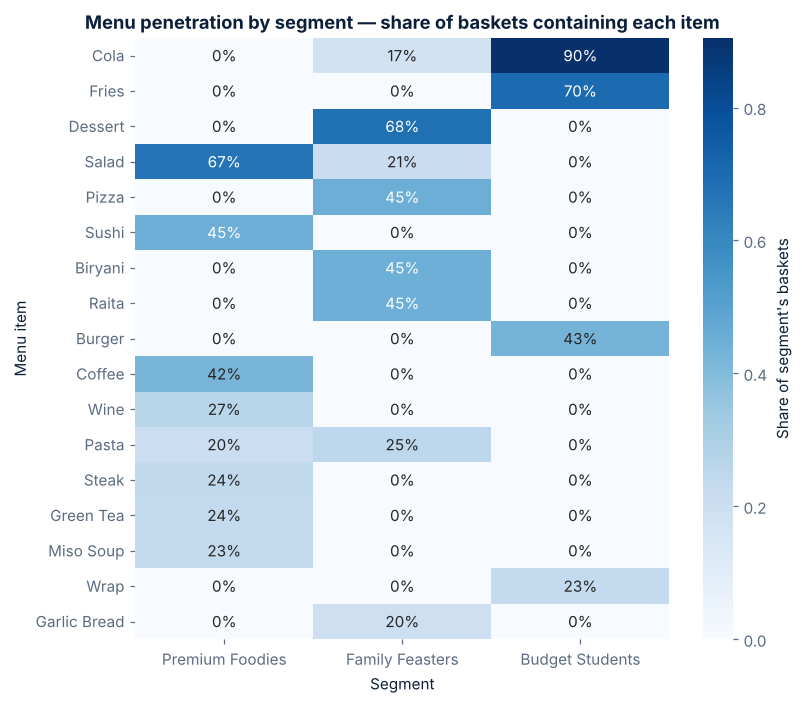

Items bought by ≥2 segments (>2% of baskets): ['Cola', 'Salad', 'Pasta']


In [31]:
share_mat = pd.DataFrame(seg_item_share).fillna(0)[SEG_ORDER]
share_mat.index = [pretty_item(i) for i in share_mat.index]
share_mat = share_mat.loc[share_mat.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
sns.heatmap(share_mat, annot=True, fmt=".0%", cmap="Blues", ax=ax, cbar_kws={"label": "Share of segment's baskets"})
ax.set(title="Menu penetration by segment — share of baskets containing each item", xlabel="Segment", ylabel="Menu item"); no_grid(ax)
savefig(fig, "item_share_by_segment")
universal = [i for i in share_mat.index if (share_mat.loc[i] > 0.02).sum() >= 2]
print("Items bought by ≥2 segments (>2% of baskets):", universal)

In [32]:
# Segment × bundle opportunity matrix (executive view: only the strongest, decision-grade rules)
def opportunity(seg, row):
    a, c = row.antecedent, row.consequent
    if row.lift < 1.5:
        return (f"Weak association (lift {row.lift:.2f}) — {c} is already in most baskets; "
                f"use a fixed-price meal deal rather than spending on a cross-sell prompt.")
    return f"Bundle {a} + {c} as a set menu; prompt {c} at checkout when {a} is in the cart."

opp_rows = []
for s in SEG_ORDER:
    r = seg_rules[s]
    cand = r[(r.tier == "Strategic") & (r.support >= 0.10)]     # decision-grade only; fall back to the single best rule
    cand = distinct_bundles(cand, 2) if len(cand) else distinct_bundles(r, 1)
    for _, row in cand.iterrows():
        opp_rows.append({"Segment": s, "If basket has (A)": row.antecedent, "Recommend (B)": row.consequent,
                         "Support": row.support, "Confidence": row.confidence, "Lift": row.lift,
                         "Business opportunity": opportunity(s, row)})
basket_opportunity = pd.DataFrame(opp_rows)
basket_opportunity

,Segment,If basket has (A),Recommend (B),Support,Confidence,Lift,Business opportunity
0,Premium Foodies,Miso Soup + Sushi,Green Tea,0.195,0.915,3.864,Bundle Miso Soup + Sushi + Green Tea as a set ...
1,Premium Foodies,Salad + Steak,Wine,0.213,0.967,3.639,Bundle Salad + Steak + Wine as a set menu; pro...
2,Family Feasters,Cola + Dessert + Pizza,Garlic Bread,0.115,0.946,4.793,Bundle Cola + Dessert + Pizza + Garlic Bread a...
3,Family Feasters,Biryani + Salad,Raita,0.171,0.945,2.113,Bundle Biryani + Salad + Raita as a set menu; ...
4,Budget Students,Cola + Wrap,Fries,0.191,0.911,1.298,Weak association (lift 1.30) — Fries is alread...


In [33]:
# reco: segment name → short list of its most-ordered items (the app.py contract)
reco = {s: seg_item_share[s].head(4).index.tolist() for s in SEG_ORDER}
assert set(reco) == set(segment_names.values())
reco

{'Premium Foodies': ['salad', 'sushi', 'coffee', 'wine'],
 'Family Feasters': ['dessert', 'pizza', 'raita', 'biryani'],
 'Budget Students': ['cola', 'fries', 'burger', 'wrap']}

## 10. Task 3 — Reorder classifier
Workflow (no leakage): clean data → X / y → **stratified train/test split** → preprocessing fitted inside a `Pipeline` on training data only → test evaluation.

In [34]:
model_df = diners[diners.include_in_classifier].reset_index(drop=True)
X, y = model_df[CLASSIFICATION_FEATURES], model_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
print(f"Modelling rows: {len(model_df)} adult diners ({len(diners) - len(model_df)} under-18 diners excluded) · train {len(X_train)} · test {len(X_test)}")
print(f"Reorder rate — train {y_train.mean():.1%} · test {y_test.mean():.1%}")

majority_class = int(y_train.mode()[0])
baseline_acc = accuracy_score(y_test, np.full(len(y_test), majority_class))
print(f"Majority-class baseline (always predict {'reorder' if majority_class else 'churn'}): accuracy {baseline_acc:.1%} on test")

Modelling rows: 460 adult diners (20 under-18 diners excluded) · train 368 · test 92
Reorder rate — train 58.4% · test 58.7%
Majority-class baseline (always predict reorder): accuracy 58.7% on test


In [35]:
def make_lr():
    return Pipeline([("scaler", StandardScaler()),
                     ("classifier", LogisticRegression(random_state=SEED, max_iter=1000))])

candidates = {
    "Logistic Regression (scaled)": make_lr(),
    "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest (300 trees)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
comp = []
for name, m in candidates.items():
    cvres = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc", "f1"])
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    comp.append({"Model": name, "CV accuracy": cvres["test_accuracy"].mean(), "CV accuracy (sd)": cvres["test_accuracy"].std(),
                 "CV ROC-AUC": cvres["test_roc_auc"].mean(), "Test accuracy": accuracy_score(y_test, p >= .5),
                 "Test ROC-AUC": roc_auc_score(y_test, p), "Test Brier (lower = better calibrated)": brier_score_loss(y_test, p),
                 "Interpretable": name.startswith(("Logistic", "Decision"))})
model_comparison = pd.DataFrame(comp).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
model_comparison

,Model,CV accuracy,CV accuracy (sd),CV ROC-AUC,Test accuracy,Test ROC-AUC,Test Brier (lower = better calibrated),Interpretable
0,Logistic Regression (scaled),0.848,0.029,0.934,0.902,0.973,0.073,True
1,Random Forest (300 trees),0.829,0.026,0.929,0.870,0.950,0.095,False
2,Gradient Boosting,0.821,0.020,0.913,0.793,0.926,0.139,False
3,Decision Tree (depth 4),0.815,0.035,0.862,0.793,0.843,0.138,True


**Model choice — Logistic Regression.** It has the best cross-validated accuracy and ROC-AUC on the training folds, the best test calibration (lowest Brier score, so its probabilities can be used directly for risk tiers), and every prediction decomposes into additive feature contributions that management can read. The tree ensembles add complexity without adding accuracy, so they are not justified. The decision is made on **cross-validation**, not on the single test split.

In [36]:
clf = candidates["Logistic Regression (scaled)"]          # fitted on X_train only
p_test = clf.predict_proba(X_test)[:, 1]
yhat = clf.predict(X_test)
cm = confusion_matrix(y_test, yhat, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
metrics = {
    "Test observations": len(y_test), "Baseline accuracy": baseline_acc, "Accuracy": accuracy_score(y_test, yhat),
    "Precision (reorder)": precision_score(y_test, yhat), "Recall (reorder)": recall_score(y_test, yhat),
    "F1 (reorder)": f1_score(y_test, yhat), "Churn recall (churners caught)": tn / (tn + fp),
    "Churn precision": tn / (tn + fn), "ROC-AUC": roc_auc_score(y_test, p_test), "Brier score": brier_score_loss(y_test, p_test),
}
metrics["Lift over baseline (pp)"] = (metrics["Accuracy"] - baseline_acc) * 100
pd.Series(metrics).to_frame("value")

,value
Test observations,92.000
Baseline accuracy,0.587
Accuracy,0.902
Precision (reorder),0.869
Recall (reorder),0.981
F1 (reorder),0.922
Churn recall (churners caught),0.789
Churn precision,0.968
ROC-AUC,0.973
Brier score,0.073


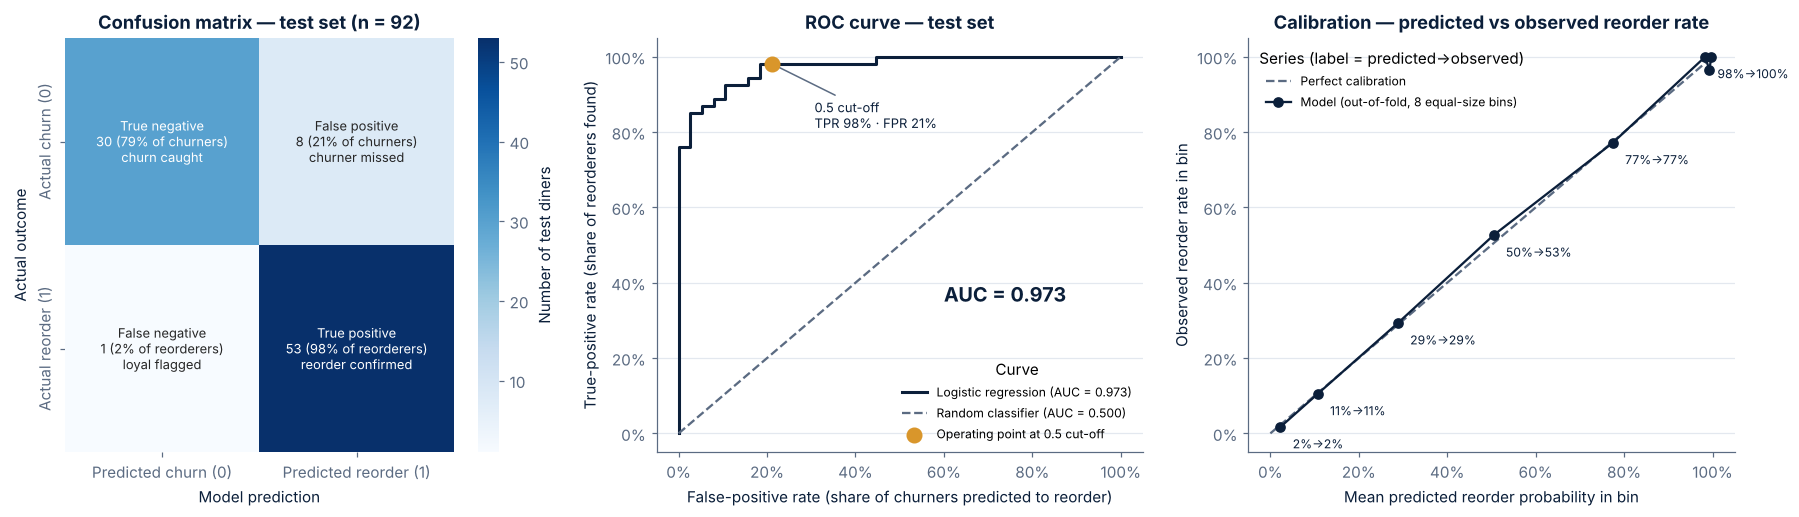

In [37]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16.5, 4.8))
row_pct = cm / cm.sum(axis=1, keepdims=True)
cm_lab = np.array([[f"True negative\n{tn} ({row_pct[0, 0]:.0%} of churners)\nchurn caught", f"False positive\n{fp} ({row_pct[0, 1]:.0%} of churners)\nchurner missed"],
                   [f"False negative\n{fn} ({row_pct[1, 0]:.0%} of reorderers)\nloyal flagged", f"True positive\n{tp} ({row_pct[1, 1]:.0%} of reorderers)\nreorder confirmed"]])
sns.heatmap(cm, annot=cm_lab, fmt="", cmap="Blues", cbar=True, ax=a1, annot_kws={"fontsize": 8.5},
            cbar_kws={"label": "Number of test diners"},
            xticklabels=["Predicted churn (0)", "Predicted reorder (1)"], yticklabels=["Actual churn (0)", "Actual reorder (1)"])
a1.set_title(f"Confusion matrix — test set (n = {len(y_test)})"); a1.set_xlabel("Model prediction"); a1.set_ylabel("Actual outcome"); no_grid(a1)
fpr, tpr, thr_roc = roc_curve(y_test, p_test)
a2.plot(fpr, tpr, color=NAVY, lw=2, label=f"Logistic regression (AUC = {metrics['ROC-AUC']:.3f})")
a2.plot([0, 1], [0, 1], "--", color=SLATE, label="Random classifier (AUC = 0.500)")
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)
a2.scatter([op_fpr], [op_tpr], s=90, color=CAUTION, zorder=5, label="Operating point at 0.5 cut-off")
a2.annotate(f"0.5 cut-off\nTPR {op_tpr:.0%} · FPR {op_fpr:.0%}", (op_fpr, op_tpr), textcoords="offset points", xytext=(28, -42),
            fontsize=8.5, color=NAVY, arrowprops=dict(arrowstyle="-", color=SLATE))
a2.text(0.6, 0.35, f"AUC = {metrics['ROC-AUC']:.3f}", fontsize=13, color=NAVY, weight="bold")
a2.set(title="ROC curve — test set", xlabel="False-positive rate (share of churners predicted to reorder)", ylabel="True-positive rate (share of reorderers found)")
a2.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
a2.legend(loc="lower right", title="Curve", fontsize=8)
# Calibration uses out-of-fold predictions on the full modelling set for a stable estimate
oof_prob = cross_val_predict(make_lr(), X, y, cv=cv, method="predict_proba")[:, 1]
frac_pos, mean_pred = calibration_curve(y, oof_prob, n_bins=8, strategy="quantile")
a3.plot([0, 1], [0, 1], "--", color=SLATE, label="Perfect calibration")
a3.plot(mean_pred, frac_pos, "-o", color=NAVY, label="Model (out-of-fold, 8 equal-size bins)")
last_x = -1
for mp_, fp_ in zip(mean_pred, frac_pos):
    if mp_ - last_x >= 0.07:                                    # skip labels that would overlap near 100%
        a3.annotate(f"{mp_:.0%}→{fp_:.0%}", (mp_, fp_), textcoords="offset points", xytext=(8, -14), fontsize=8, color=NAVY)
        last_x = mp_
a3.set(title="Calibration — predicted vs observed reorder rate", xlabel="Mean predicted reorder probability in bin", ylabel="Observed reorder rate in bin")
a3.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a3.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
a3.legend(loc="upper left", title="Series (label = predicted→observed)", fontsize=8)
savefig(fig, "classifier_cm_roc_calibration")

### How precise are these numbers? Bootstrap confidence intervals & repeated cross-validation
A single 96-diner test set is small, so each metric carries sampling error. Two complementary checks:
- **Bootstrap 95% CI**: resample the test set 2,000 times and recompute every metric.
- **Repeated stratified 5-fold CV (10 repeats = 50 fits)** on all adult diners: a more stable estimate than one split. The model is refit inside every fold (no leakage).

Repeated CV (50 fits): accuracy 85.8% ± 3.0% · ROC-AUC 0.944 ± 0.018 · baseline 58.5%
Single test split accuracy 90.2% sits within the 5th–95th percentile of repeated-CV folds (80.4%–90.2%).


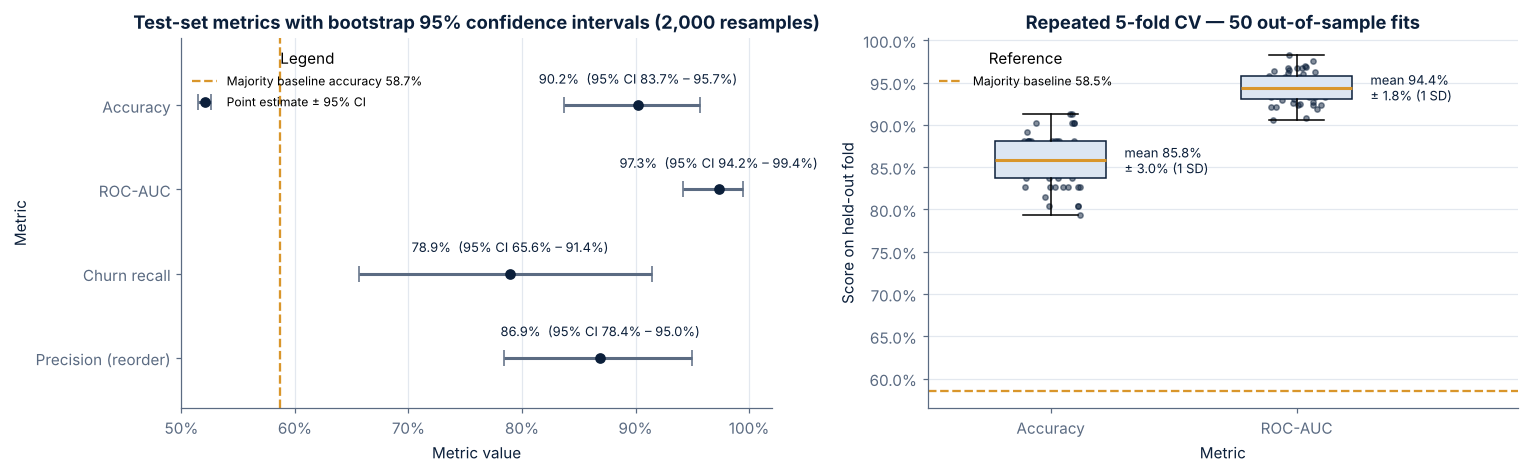

,Metric,Point estimate,95% CI low,95% CI high
0,Accuracy,0.902,0.837,0.957
1,ROC-AUC,0.973,0.942,0.994
2,Churn recall,0.789,0.656,0.914
3,Precision (reorder),0.869,0.784,0.950
4,Lift over baseline (pp),31.522,21.739,40.217


In [38]:
from sklearn.model_selection import RepeatedStratifiedKFold
rng = np.random.default_rng(SEED)
yt, pt = y_test.to_numpy(), p_test
boot = {"Accuracy": [], "ROC-AUC": [], "Churn recall": [], "Precision (reorder)": [], "Lift over baseline (pp)": []}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    yb, pb = yt[i], pt[i]
    if yb.min() == yb.max():
        continue
    yh = (pb >= .5).astype(int)
    acc_b = (yh == yb).mean()
    boot["Accuracy"].append(acc_b); boot["ROC-AUC"].append(roc_auc_score(yb, pb))
    boot["Churn recall"].append(((yh == 0) & (yb == 0)).sum() / (yb == 0).sum())
    boot["Precision (reorder)"].append(((yh == 1) & (yb == 1)).sum() / max((yh == 1).sum(), 1))
    boot["Lift over baseline (pp)"].append((acc_b - max(yb.mean(), 1 - yb.mean())) * 100)
point = {"Accuracy": metrics["Accuracy"], "ROC-AUC": metrics["ROC-AUC"], "Churn recall": metrics["Churn recall (churners caught)"],
         "Precision (reorder)": metrics["Precision (reorder)"], "Lift over baseline (pp)": metrics["Lift over baseline (pp)"]}
bootstrap_ci = pd.DataFrame([{"Metric": k, "Point estimate": point[k], "95% CI low": np.percentile(v, 2.5),
                              "95% CI high": np.percentile(v, 97.5)} for k, v in boot.items()])

rcv = cross_validate(make_lr(), X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED),
                     scoring=["accuracy", "roc_auc"])
fold_baseline = max(y.mean(), 1 - y.mean())
repeated_cv = {"acc_mean": rcv["test_accuracy"].mean(), "acc_sd": rcv["test_accuracy"].std(),
               "auc_mean": rcv["test_roc_auc"].mean(), "auc_sd": rcv["test_roc_auc"].std(),
               "acc_p5": np.percentile(rcv["test_accuracy"], 5), "acc_p95": np.percentile(rcv["test_accuracy"], 95),
               "n_fits": len(rcv["test_accuracy"]), "baseline": fold_baseline}
cv_scores = pd.DataFrame({"Accuracy": rcv["test_accuracy"], "ROC-AUC": rcv["test_roc_auc"]})
print(f"Repeated CV (50 fits): accuracy {repeated_cv['acc_mean']:.1%} ± {repeated_cv['acc_sd']:.1%} · "
      f"ROC-AUC {repeated_cv['auc_mean']:.3f} ± {repeated_cv['auc_sd']:.3f} · baseline {fold_baseline:.1%}")
print(f"Single test split accuracy {metrics['Accuracy']:.1%} sits "
      f"{'within' if repeated_cv['acc_p5'] <= metrics['Accuracy'] <= repeated_cv['acc_p95'] else 'outside'} the 5th–95th percentile "
      f"of repeated-CV folds ({repeated_cv['acc_p5']:.1%}–{repeated_cv['acc_p95']:.1%}).")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.4))
bc = bootstrap_ci[bootstrap_ci.Metric != "Lift over baseline (pp)"].reset_index(drop=True)
ypos = np.arange(len(bc))[::-1]
a1.errorbar(bc["Point estimate"], ypos, xerr=[bc["Point estimate"] - bc["95% CI low"], bc["95% CI high"] - bc["Point estimate"]],
            fmt="o", color=NAVY, ecolor=SLATE, capsize=5, lw=2, label="Point estimate ± 95% CI")
for yp, (_, r_) in zip(ypos, bc.iterrows()):
    a1.text(r_["Point estimate"], yp + 0.22, f"{r_['Point estimate']:.1%}  (95% CI {r_['95% CI low']:.1%} – {r_['95% CI high']:.1%})",
            ha="center", va="bottom", fontsize=8.5, color=NAVY)
a1.axvline(baseline_acc, color=CAUTION, ls="--", lw=1.5, label=f"Majority baseline accuracy {baseline_acc:.1%}")
a1.set_yticks(ypos); a1.set_yticklabels(bc.Metric)
a1.set(title="Test-set metrics with bootstrap 95% confidence intervals (2,000 resamples)", xlabel="Metric value", ylabel="Metric")
a1.set_xlim(0.5, 1.02); a1.set_ylim(-0.6, len(bc) - 0.2); a1.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
a1.legend(loc="upper left", fontsize=8, title="Legend"); x_grid(a1)
bp = a2.boxplot([cv_scores.Accuracy, cv_scores["ROC-AUC"]], tick_labels=["Accuracy", "ROC-AUC"], widths=.45, patch_artist=True,
                boxprops=dict(facecolor="#DCE6F2", color=NAVY), medianprops=dict(color=CAUTION, lw=2))
for i_, col_ in enumerate(["Accuracy", "ROC-AUC"], start=1):
    a2.scatter(np.full(len(cv_scores), i_) + rng.uniform(-.12, .12, len(cv_scores)), cv_scores[col_], s=12, color=NAVY, alpha=.5)
    m_, sd_ = cv_scores[col_].mean(), cv_scores[col_].std()
    a2.text(i_ + .3, m_, f"mean {m_:.1%}\n± {sd_:.1%} (1 SD)", va="center", fontsize=8.5, color=NAVY)
a2.axhline(fold_baseline, color=CAUTION, ls="--", lw=1.5, label=f"Majority baseline {fold_baseline:.1%}")
a2.set(title="Repeated 5-fold CV — 50 out-of-sample fits", xlabel="Metric", ylabel="Score on held-out fold")
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a2.legend(loc="upper left", title="Reference", fontsize=8)
a2.set_xlim(0.5, 2.9)
savefig(fig, "classifier_uncertainty")
bootstrap_ci

**Reading:** the reorder model beats the baseline by a wide margin in *every* resample and every fold — the lower bound of the accuracy CI sits well above the 58–60% majority baseline. Repeated CV is the number to quote for expected real-world accuracy; the single test-split figure is one draw from that distribution and its CI shows the plausible range.

**Reading the errors (positive class = reorder):**
- **False positive** — predicted *reorder*, but the diner *churned*. QuickBite does nothing and loses the customer. **This is the costlier error**: the lost value is roughly a month of spend (≈ AED 550–870 per diner on segment averages) and acquisition is expensive.
- **False negative** — predicted *churn*, but the diner *reordered*. QuickBite sends an unnecessary offer; the cost is the discount (a fraction of one order).

Because missed churners cost more than wasted offers, the model should be used as a **ranking tool**: target retention spend by probability band (below) rather than relying only on the default 0.5 cut-off that `clf.predict` uses.

In [39]:
# Threshold trade-off: how many churners are caught vs how many loyal diners receive an offer
thr_rows = []
for t in [0.4, 0.5, 0.6, 0.7]:
    flag = oof_prob < t                                           # "at risk" if reorder probability < t
    thr_rows.append({"Flag as at-risk if P(reorder) <": t, "Churners caught": (flag & (y == 0)).sum() / (y == 0).sum(),
                     "Loyal diners sent an offer": (flag & (y == 1)).sum() / (y == 1).sum(), "Diners targeted": int(flag.sum())})
threshold_table = pd.DataFrame(thr_rows)
threshold_table

,Flag as at-risk if P(reorder) <,Churners caught,Loyal diners sent an offer,Diners targeted
0,0.400,0.780,0.093,174
1,0.500,0.869,0.145,205
2,0.600,0.916,0.182,224
3,0.700,0.948,0.257,250


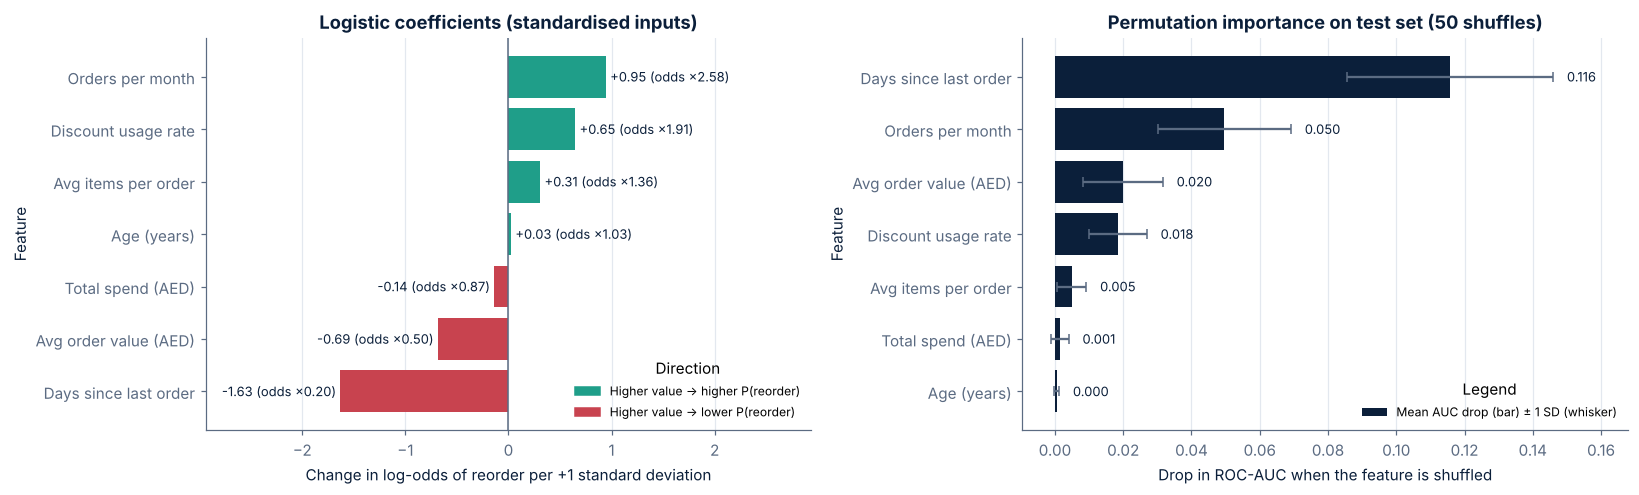

,"Coefficient (per 1 SD, log-odds)",Odds ratio per 1 SD,Permutation importance (AUC drop),Permutation sd
days_since_last_order,-1.631,0.196,0.116,0.030
orders_per_month,0.947,2.577,0.050,0.020
avg_order_value,-0.686,0.504,0.020,0.012
discount_rate,0.650,1.915,0.018,0.008
avg_items_per_order,0.310,1.363,0.005,0.004
total_spend,-0.139,0.870,0.001,0.003
age,0.027,1.027,0.000,0.001


In [40]:
coef = pd.Series(clf.named_steps["classifier"].coef_[0], index=CLASSIFICATION_FEATURES)
perm = permutation_importance(clf, X_test, y_test, scoring="roc_auc", n_repeats=50, random_state=SEED)
importance = pd.DataFrame({"Coefficient (per 1 SD, log-odds)": coef, "Odds ratio per 1 SD": np.exp(coef),
                           "Permutation importance (AUC drop)": perm.importances_mean,
                           "Permutation sd": perm.importances_std}).sort_values("Permutation importance (AUC drop)", ascending=False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6))
c_sorted = coef.sort_values()
bars = a1.barh([LABELS[c] for c in c_sorted.index], c_sorted.values, color=[POS if v > 0 else RISK for v in c_sorted.values])
for b_, v_, c_ in zip(bars, c_sorted.values, c_sorted.index):
    a1.text(v_ + (0.04 if v_ >= 0 else -0.04), b_.get_y() + b_.get_height() / 2, f"{v_:+.2f} (odds ×{np.exp(v_):.2f})",
            va="center", ha="left" if v_ >= 0 else "right", fontsize=8.5, color=NAVY)
a1.axvline(0, color=SLATE, lw=1)
lim = np.abs(c_sorted).max() * 1.8; a1.set_xlim(-lim, lim)
a1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=POS), plt.Rectangle((0, 0), 1, 1, color=RISK)],
          labels=["Higher value → higher P(reorder)", "Higher value → lower P(reorder)"], title="Direction", loc="lower right", fontsize=8)
a1.set(title="Logistic coefficients (standardised inputs)", xlabel="Change in log-odds of reorder per +1 standard deviation", ylabel="Feature"); x_grid(a1)
imp = importance["Permutation importance (AUC drop)"].sort_values()
bars = a2.barh([LABELS[c] for c in imp.index], imp.values, xerr=importance.loc[imp.index, "Permutation sd"], color=NAVY,
               error_kw=dict(ecolor=SLATE, capsize=3), label="Mean AUC drop (bar) ± 1 SD (whisker)")
for b_, v_, sd_ in zip(bars, imp.values, importance.loc[imp.index, "Permutation sd"]):
    a2.text(max(v_, 0) + sd_ + 0.004, b_.get_y() + b_.get_height() / 2, f"{v_:.3f}", va="center", fontsize=8.5, color=NAVY)
a2.set_xlim(min(0, imp.min() - 0.01), imp.max() * 1.45)
a2.set(title="Permutation importance on test set (50 shuffles)", xlabel="Drop in ROC-AUC when the feature is shuffled", ylabel="Feature")
a2.legend(loc="lower right", fontsize=8, title="Legend"); x_grid(a2)
savefig(fig, "classifier_importance")
importance

**Interpretation (associations, not causes).** Recency is the dominant predictive signal: each additional standard deviation (~7 days) since the last order is associated with markedly lower odds of reordering. Higher frequency and discount use are associated with higher predicted probability; higher order value with lower. Because frequency, order value and basket size are highly collinear (VIF > 5) and also track age, these coefficients describe the *joint* behavioural profile — e.g. "frequent, low-ticket, discount-using diners reorder" — rather than independent levers.

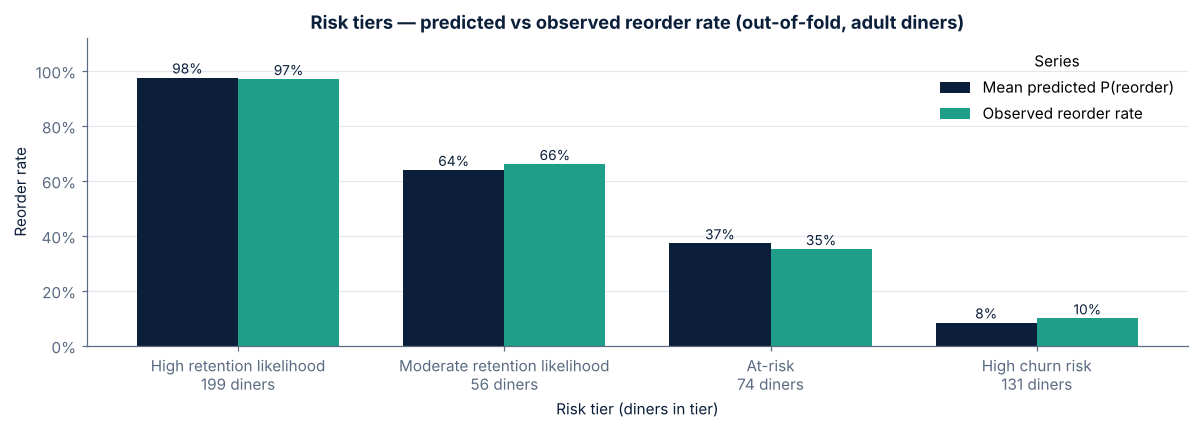

,Diners,Mean predicted P(reorder),Observed reorder rate,Est. monthly spend at stake (AED)
risk_tier,,,,
High retention likelihood,199,0.976,0.970,"114,863.980"
Moderate retention likelihood,56,0.639,0.661,"47,285.950"
At-risk,74,0.372,0.351,"58,620.800"
High churn risk,131,0.084,0.099,"86,094.950"


In [41]:
# Risk framework on out-of-fold probabilities (honest: each diner scored by a model that did not see them)
RISK_TIERS = [  # (lower bound, label, intervention, colour)
    (0.75, "High retention likelihood", "Loyalty reward / premium upsell — no discount needed", POS),
    (0.50, "Moderate retention likelihood", "Personalised promotion on segment favourites", "#6FAF9F"),
    (0.25, "At-risk", "Targeted retention offer within 7 days", CAUTION),
    (0.00, "High churn risk", "Win-back offer on favourite bundle + reminder", RISK),
]
def risk_tier(p):
    for lo, lab, *_ in RISK_TIERS:
        if p >= lo:
            return lab

model_df["reorder_prob_oof"] = oof_prob
model_df["risk_tier"] = model_df.reorder_prob_oof.map(risk_tier)
tier_order = [t[1] for t in RISK_TIERS]
tier_summary = model_df.groupby("risk_tier").agg(Diners=("diner_id", "size"), **{"Mean predicted P(reorder)": ("reorder_prob_oof", "mean"),
                                                 "Observed reorder rate": (TARGET, "mean"),
                                                 "Est. monthly spend at stake (AED)": ("est_monthly_spend", "sum")}).reindex(tier_order)

fig, ax = plt.subplots(figsize=(11, 4))
x_ = np.arange(len(tier_order)); w_ = 0.38
b1 = ax.bar(x_ - w_ / 2, tier_summary["Mean predicted P(reorder)"], w_, color=NAVY, label="Mean predicted P(reorder)")
b2 = ax.bar(x_ + w_ / 2, tier_summary["Observed reorder rate"], w_, color=POS, label="Observed reorder rate")
for bars_ in (b1, b2):
    for b_ in bars_:
        ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + .015, f"{b_.get_height():.0%}", ha="center", fontsize=9, color=NAVY)
ax.set_xticks(x_); ax.set_xticklabels([f"{t}\n{int(n)} diners" for t, n in zip(tier_order, tier_summary.Diners)])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, 1.12)
ax.set(title="Risk tiers — predicted vs observed reorder rate (out-of-fold, adult diners)", xlabel="Risk tier (diners in tier)", ylabel="Reorder rate")
ax.legend(title="Series", loc="upper right")
savefig(fig, "risk_tiers")
tier_summary

**Why these cut-offs?** The bands are quartiles of the probability scale, and the out-of-fold table shows they are **monotone and well calibrated**: observed reorder rates rise steadily across tiers and sit close to the mean predicted probability in each. 0.5 is kept as the boundary between "retained" and "at-risk" so the tiers agree with `clf.predict`.

## 11. Management priority & action matrices — value × retention risk

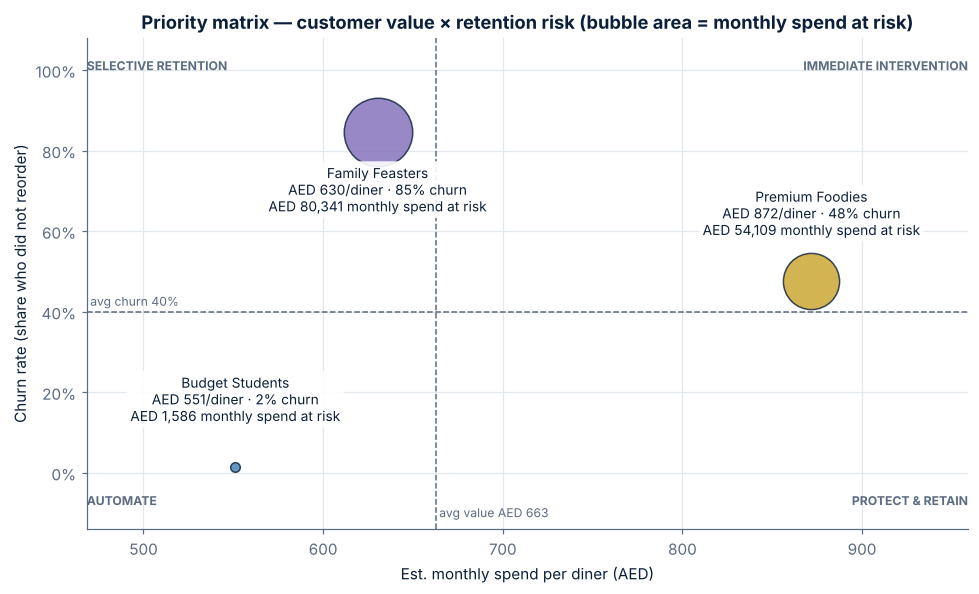

,diners_n,value,churn,revenue,pred_churn,revenue_at_risk,quadrant,movable_diners,movable_value,lapsed_diners,intervention_rank
segment,,,,,,,,,,,
Premium Foodies,130,871.794,0.477,"113,333.170",0.479,"54,109.474",High value / High risk → Immediate intervention,101,"88,385.160",12,1
Family Feasters,150,630.284,0.847,"94,542.660",0.849,"80,341.150",Low value / High risk → Selective retention spend,29,"17,521.590",119,2
Budget Students,200,551.104,0.015,"110,220.860",0.010,"1,585.865",Low value / Low risk → Automate & maintain eff...,0,0.000,0,3


In [42]:
diners = diners.merge(model_df[["diner_id", "reorder_prob_oof", "risk_tier"]], on="diner_id", how="left")
seg_econ = diners.groupby("segment").agg(diners_n=("diner_id", "size"), value=("est_monthly_spend", "mean"),
                                        churn=(TARGET, lambda s: 1 - s.mean()), revenue=("est_monthly_spend", "sum"),
                                        pred_churn=("reorder_prob_oof", lambda s: 1 - s.mean())).loc[SEG_ORDER]
# Under-18 diners are not scored by the classifier; for value-at-risk they contribute their observed outcome.
seg_econ["revenue_at_risk"] = (diners.assign(rar=diners.est_monthly_spend * (1 - diners.reorder_prob_oof.fillna(diners[TARGET])))
                               .groupby("segment").rar.sum().loc[SEG_ORDER])
VALUE_CUT, RISK_CUT = diners.est_monthly_spend.mean(), 1 - diners[TARGET].mean()
def quadrant(v, r):
    if v >= VALUE_CUT and r >= RISK_CUT: return "High value / High risk → Immediate intervention"
    if v >= VALUE_CUT: return "High value / Low risk → Protect & retain"
    if r >= RISK_CUT: return "Low value / High risk → Selective retention spend"
    return "Low value / Low risk → Automate & maintain efficiently"
seg_econ["quadrant"] = [quadrant(v, r) for v, r in zip(seg_econ.value, seg_econ.churn)]
# "Movable" value: spend of diners whose reorder probability is genuinely uncertain (25–75%).
# Retention budget has the most leverage here; diners <25% are largely lapsed, >75% will return anyway.
movable = diners.reorder_prob_oof.between(0.25, 0.75, inclusive="left")
seg_econ["movable_diners"] = diners[movable].groupby("segment").size().reindex(SEG_ORDER).fillna(0).astype(int)
seg_econ["movable_value"] = diners[movable].groupby("segment").est_monthly_spend.sum().reindex(SEG_ORDER).fillna(0)
seg_econ["lapsed_diners"] = diners[diners.reorder_prob_oof < 0.25].groupby("segment").size().reindex(SEG_ORDER).fillna(0).astype(int)
seg_econ["intervention_rank"] = seg_econ.movable_value.rank(ascending=False).astype(int)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.axvline(VALUE_CUT, color=SLATE, ls="--", lw=1); ax.axhline(RISK_CUT, color=SLATE, ls="--", lw=1)
for s, r in seg_econ.iterrows():
    ax.scatter(r.value, r.churn, s=r.revenue_at_risk / 40, color=SEG_COLORS[s], alpha=.8, edgecolor=NAVY)
    ax.annotate(f"{s}\nAED {r.value:,.0f}/diner · {r.churn:.0%} churn\nAED {r.revenue_at_risk:,.0f} monthly spend at risk", (r.value, r.churn),
                textcoords="offset points", xytext=(0, -52 if r.churn > .5 else 30), ha="center", color=NAVY, fontsize=9,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=.9))
ax.set(title="Priority matrix — customer value × retention risk (bubble area = monthly spend at risk)",
       xlabel="Est. monthly spend per diner (AED)", ylabel="Churn rate (share who did not reorder)")
ax.text(VALUE_CUT, -.11, f" avg value AED {VALUE_CUT:,.0f}", color=SLATE, fontsize=8)
ax.text(lo_v_ := seg_econ.value.min() * .85, RISK_CUT + .015, f" avg churn {RISK_CUT:.0%}", color=SLATE, fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(-.14, 1.08)
lo_v, hi_v = lo_v_, seg_econ.value.max() * 1.1; ax.set_xlim(lo_v, hi_v)
ax.grid(True, color=GRID)
for x, yv, t in [(hi_v, 1.0, "IMMEDIATE INTERVENTION"), (hi_v, -.08, "PROTECT & RETAIN"), (lo_v, 1.0, "SELECTIVE RETENTION"), (lo_v, -.08, "AUTOMATE")]:
    ax.text(x, yv, t, ha="right" if x == hi_v else "left", color=SLATE, fontsize=8, weight="bold")
savefig(fig, "priority_matrix")
seg_econ

**Reading the matrix.** Premium Foodies are the only *high-value, high-risk* segment. Family Feasters carry the largest gross spend at risk, but most of them are already below a 25% reorder probability — they have largely lapsed, so retention money buys less there. The **movable value** column (spend held by diners whose outcome is genuinely uncertain, 25–75%) is where intervention has the most leverage, and it is concentrated in Premium Foodies. Intervention rank is therefore set by movable value, not gross exposure.

In [43]:
best_bundle = {s: (basket_opportunity[basket_opportunity.Segment == s].iloc[0]["If basket has (A)"] + " + "
                   + basket_opportunity[basket_opportunity.Segment == s].iloc[0]["Recommend (B)"]) for s in SEG_ORDER}
KEY_BEHAVIOUR = {s: f"{seg_profile.loc[s, 'Orders / month']:.1f} orders/mo · AED {seg_profile.loc[s, 'Avg order value (AED)']:.0f} AOV · "
                    f"{seg_profile.loc[s, 'Discount usage']:.0%} discounted" for s in SEG_ORDER}
segment_action = pd.DataFrame({
    "Segment": SEG_ORDER,
    "Value (est. AED / diner / month)": [seg_econ.loc[s, "value"] for s in SEG_ORDER],
    "Retention risk (churn rate)": [seg_econ.loc[s, "churn"] for s in SEG_ORDER],
    "Key behaviour": [KEY_BEHAVIOUR[s] for s in SEG_ORDER],
    "Best bundle": [best_bundle[s] for s in SEG_ORDER],
    "Quadrant": [seg_econ.loc[s, "quadrant"] for s in SEG_ORDER],
    "Recommended action": [SEGMENT_STRATEGY[s]["action"] for s in SEG_ORDER],
})
segment_action

,Segment,Value (est. AED / diner / month),Retention risk (churn rate),Key behaviour,Best bundle,Quadrant,Recommended action
0,Premium Foodies,871.794,0.477,9.0 orders/mo · AED 97 AOV · 10% discounted,Miso Soup + Sushi + Green Tea,High value / High risk → Immediate intervention,"PROTECT & UPSELL: tiered loyalty, premium pair..."
1,Family Feasters,630.284,0.847,3.6 orders/mo · AED 174 AOV · 31% discounted,Cola + Dessert + Pizza + Garlic Bread,Low value / High risk → Selective retention spend,WIN-BACK SELECTIVELY: time-boxed family-bundle...
2,Budget Students,551.104,0.015,13.1 orders/mo · AED 42 AOV · 62% discounted,Cola + Wrap + Fries,Low value / Low risk → Automate & maintain eff...,MAINTAIN EFFICIENTLY: automated meal-deal bund...


### Revenue concentration — how dependent is QuickBite on its top diners?
A Lorenz curve ranks diners from highest to lowest estimated monthly spend and plots the cumulative share of revenue. The Gini coefficient summarises concentration (0 = every diner spends the same, 1 = one diner holds all revenue).

Gini = 0.181; Top 10% of diners → 16.3% of revenue; Top 20% of diners → 29.7% of revenue; Top 50% of diners → 62.8% of revenue
Segment mix of the top 20% of diners by spend: {'Premium Foodies': '73%', 'Family Feasters': '23%', 'Budget Students': '4%'}


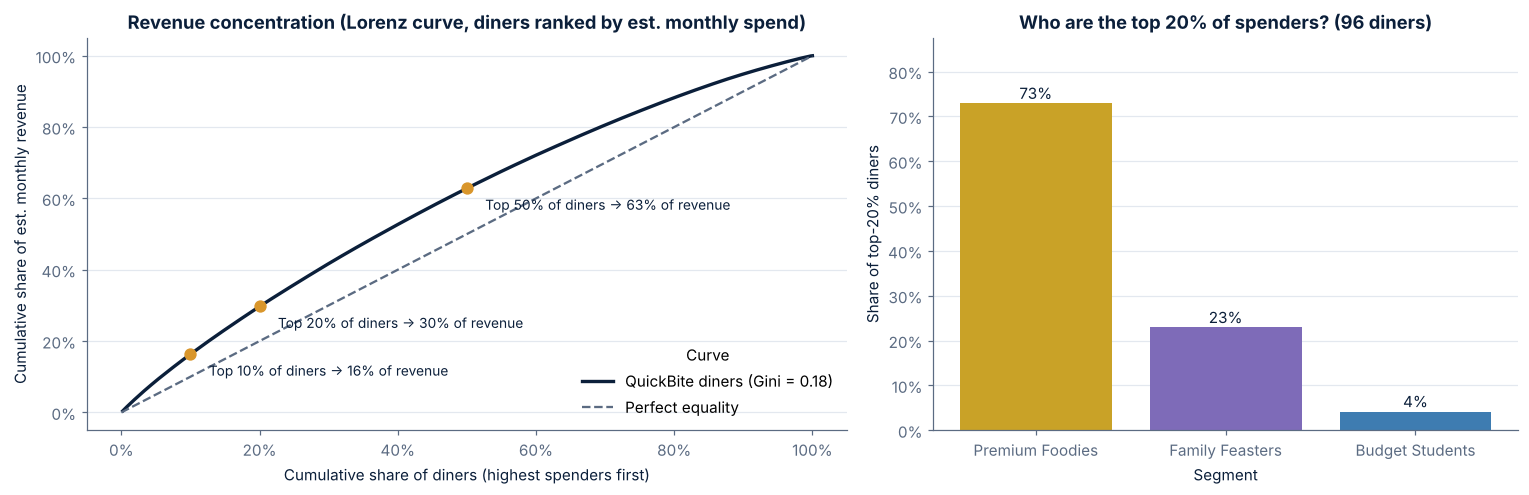

In [44]:
spend_sorted = np.sort(diners.est_monthly_spend.to_numpy())[::-1]
cum_rev = np.cumsum(spend_sorted) / spend_sorted.sum()
cum_pop = np.arange(1, len(spend_sorted) + 1) / len(spend_sorted)
asc = np.sort(spend_sorted); n_ = len(asc)
gini = (2 * np.sum(np.arange(1, n_ + 1) * asc) / (n_ * asc.sum())) - (n_ + 1) / n_
conc = {f"Top {int(q * 100)}%": float(cum_rev[int(np.ceil(q * n_)) - 1]) for q in (0.1, 0.2, 0.5)}
top20_mix = diners.nlargest(int(0.2 * n_), "est_monthly_spend").segment.value_counts(normalize=True).reindex(SEG_ORDER).fillna(0)
print(f"Gini = {gini:.3f}; " + "; ".join(f"{k} of diners → {v:.1%} of revenue" for k, v in conc.items()))
print("Segment mix of the top 20% of diners by spend:", {k: f"{v:.0%}" for k, v in top20_mix.items()})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
a1.plot(cum_pop, cum_rev, color=NAVY, lw=2.2, label=f"QuickBite diners (Gini = {gini:.2f})")
a1.plot([0, 1], [0, 1], "--", color=SLATE, label="Perfect equality")
for k_, q_ in zip(conc, (0.1, 0.2, 0.5)):
    a1.scatter([q_], [conc[k_]], color=CAUTION, zorder=5, s=50)
    a1.annotate(f"{k_} of diners → {conc[k_]:.0%} of revenue", (q_, conc[k_]), textcoords="offset points", xytext=(12, -14), fontsize=9, color=NAVY)
a1.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
a1.set(title="Revenue concentration (Lorenz curve, diners ranked by est. monthly spend)", xlabel="Cumulative share of diners (highest spenders first)",
       ylabel="Cumulative share of est. monthly revenue")
a1.legend(loc="lower right", title="Curve")
bars = a2.bar(SEG_ORDER, top20_mix.values, color=[SEG_COLORS[s_] for s_ in SEG_ORDER])
for b_, v_ in zip(bars, top20_mix.values):
    a2.text(b_.get_x() + b_.get_width() / 2, v_ + .01, f"{v_:.0%}", ha="center", color=NAVY)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a2.set_ylim(0, max(top20_mix.max() * 1.2, .1))
a2.set(title=f"Who are the top 20% of spenders? ({int(0.2 * n_)} diners)", xlabel="Segment", ylabel="Share of top-20% diners")
savefig(fig, "revenue_concentration")

**Reading:** revenue is only mildly concentrated (Gini well below 0.5) — QuickBite does not depend on a handful of whales, so losing any single diner is not material; churn matters in aggregate. The top-spending fifth is dominated by Premium Foodies, which reinforces them as the segment to protect.

### Retention campaign economics — who is worth targeting?
A retention offer only makes sense if its expected recovered margin exceeds its cost. Using the **calibrated out-of-fold probabilities**, for each adult diner:

expected value of an offer = P(churn) × success rate × monthly spend × months of spend recovered × gross margin − offer cost

**Assumptions (deliberately conservative and illustrative — the dashboard lets management change them):** offer cost AED 25 (≈ a 25% discount on a typical order), gross margin 25%, 10% of would-be churners retained by the offer, 2 months of spend recovered. These are planning assumptions, not estimates from this data; the success rate in particular must be measured with an A/B test.

Probability cut-off that maximises net value: P(reorder) < 0.35 → 162 diners, net AED 694, ROI 17%
Value-ranked targeting: 128 diners, net AED 1,107 (+AED 413 vs the best probability cut-off)
Value-ranked targets by segment: {'Premium Foodies': 44, 'Family Feasters': 84, 'Budget Students': 0}


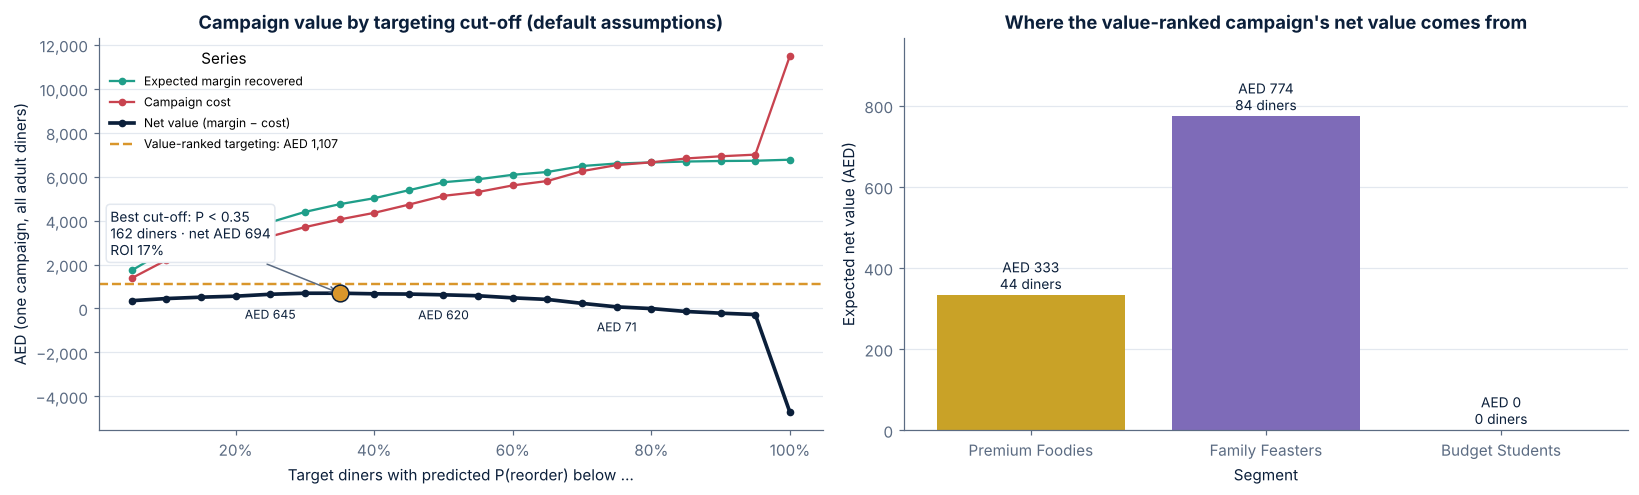

,threshold,targeted,cost,exp_margin,net,roi,saved_diners
0,0.050,55,"1,375.000","1,727.783",352.783,0.257,5.382
1,0.100,88,"2,200.000","2,650.099",450.099,0.205,8.445
2,0.150,104,"2,600.000","3,112.528",512.528,0.197,9.847
3,0.200,116,"2,900.000","3,457.763",557.763,0.192,10.836
4,0.250,131,"3,275.000","3,920.211",645.211,0.197,11.993
5,0.300,148,"3,700.000","4,392.179",692.179,0.187,13.235
6,0.350,162,"4,050.000","4,743.661",693.661,0.171,14.186
7,0.400,174,"4,350.000","5,016.326",666.326,0.153,14.943
8,0.450,189,"4,725.000","5,380.031",655.031,0.139,15.804
9,0.500,205,"5,125.000","5,745.209",620.209,0.121,16.637


In [45]:
ROI_DEFAULTS = dict(offer_cost=25.0, margin=0.25, success=0.10, horizon=2)

def campaign_value(df, threshold, offer_cost, margin, success, horizon):
    tgt = df[df.reorder_prob_oof < threshold]
    exp_margin = ((1 - tgt.reorder_prob_oof) * success * tgt.est_monthly_spend * horizon * margin).sum()
    cost = offer_cost * len(tgt)
    return {"threshold": threshold, "targeted": len(tgt), "cost": cost, "exp_margin": exp_margin, "net": exp_margin - cost,
            "roi": (exp_margin - cost) / cost if cost else np.nan, "saved_diners": ((1 - tgt.reorder_prob_oof) * success).sum()}

scored = diners[diners.reorder_prob_oof.notna()].copy()
grid_t = np.round(np.arange(0.05, 1.0001, 0.05), 2)
roi_curve = pd.DataFrame([campaign_value(scored, t, **ROI_DEFAULTS) for t in grid_t])
best_t = roi_curve.loc[roi_curve.net.idxmax()]
# Value-ranked targeting: offer only to diners whose individual expected value is positive
scored["exp_value"] = (1 - scored.reorder_prob_oof) * ROI_DEFAULTS["success"] * scored.est_monthly_spend * ROI_DEFAULTS["horizon"] * ROI_DEFAULTS["margin"] - ROI_DEFAULTS["offer_cost"]
vr = scored[scored.exp_value > 0]
value_ranked = {"targeted": len(vr), "net": vr.exp_value.sum(), "cost": ROI_DEFAULTS["offer_cost"] * len(vr)}
print(f"Probability cut-off that maximises net value: P(reorder) < {best_t.threshold:.2f} → {int(best_t.targeted)} diners, "
      f"net AED {best_t.net:,.0f}, ROI {best_t.roi:.0%}")
print(f"Value-ranked targeting: {value_ranked['targeted']} diners, net AED {value_ranked['net']:,.0f} "
      f"(+AED {value_ranked['net'] - best_t.net:,.0f} vs the best probability cut-off)")
print("Value-ranked targets by segment:", vr.segment.value_counts().reindex(SEG_ORDER).fillna(0).astype(int).to_dict())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6))
a1.plot(roi_curve.threshold, roi_curve.exp_margin, "-o", color=POS, ms=4, label="Expected margin recovered")
a1.plot(roi_curve.threshold, roi_curve.cost, "-o", color=RISK, ms=4, label="Campaign cost")
a1.plot(roi_curve.threshold, roi_curve.net, "-o", color=NAVY, lw=2.4, ms=4, label="Net value (margin − cost)")
a1.axhline(value_ranked["net"], color=CAUTION, ls="--", lw=1.6, label=f"Value-ranked targeting: AED {value_ranked['net']:,.0f}")
a1.scatter([best_t.threshold], [best_t.net], s=120, color=CAUTION, edgecolor=NAVY, zorder=5)
a1.annotate(f"Best cut-off: P < {best_t.threshold:.2f}\n{int(best_t.targeted)} diners · net AED {best_t.net:,.0f}\nROI {best_t.roi:.0%}",
            (best_t.threshold, best_t.net), textcoords="offset points", xytext=(-150, 25), fontsize=9, color=NAVY,
            arrowprops=dict(arrowstyle="->", color=SLATE), bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID))
for t_ in (0.25, 0.5, 0.75):
    r_ = roi_curve[np.isclose(roi_curve.threshold, t_)].iloc[0]
    a1.annotate(f"AED {r_.net:,.0f}", (t_, r_.net), textcoords="offset points", xytext=(0, -16), ha="center", fontsize=8, color=NAVY)
a1.set(title="Campaign value by targeting cut-off (default assumptions)", xlabel="Target diners with predicted P(reorder) below …",
       ylabel="AED (one campaign, all adult diners)")
a1.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
a1.legend(loc="upper left", fontsize=8, title="Series")
seg_val = vr.groupby("segment").exp_value.sum().reindex(SEG_ORDER).fillna(0)
seg_n = vr.segment.value_counts().reindex(SEG_ORDER).fillna(0).astype(int)
bars = a2.bar(SEG_ORDER, seg_val.values, color=[SEG_COLORS[s_] for s_ in SEG_ORDER])
for b_, v_, n_s in zip(bars, seg_val.values, seg_n.values):
    a2.text(b_.get_x() + b_.get_width() / 2, v_ + seg_val.max() * .02, f"AED {v_:,.0f}\n{n_s} diners", ha="center", fontsize=9, color=NAVY)
a2.set_ylim(0, seg_val.max() * 1.25 if seg_val.max() > 0 else 1)
a2.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
a2.set(title="Where the value-ranked campaign's net value comes from", xlabel="Segment", ylabel="Expected net value (AED)")
savefig(fig, "campaign_economics")
roi_curve.round(3)

In [46]:
# Assumption sensitivity: does value-ranking still win when the economics change?
sens_rows = []
for oc, mg, sc_, hz in [(20, .30, .25, 3), (25, .30, .15, 2), (25, .25, .10, 2), (30, .30, .15, 1), (50, .30, .20, 2)]:
    curve = pd.DataFrame([campaign_value(scored, t, oc, mg, sc_, hz) for t in grid_t])
    bt = curve.loc[curve.net.idxmax()]
    ev = (1 - scored.reorder_prob_oof) * sc_ * scored.est_monthly_spend * hz * mg - oc
    sens_rows.append({"Offer cost (AED)": oc, "Margin": f"{mg:.0%}", "Success rate": f"{sc_:.0%}", "Months recovered": hz,
                      "Best cut-off": f"P < {bt.threshold:.2f}", "Cut-off: diners": int(bt.targeted), "Cut-off: net AED": round(bt.net),
                      "Value-ranked: diners": int((ev > 0).sum()), "Value-ranked: net AED": round(ev[ev > 0].sum()),
                      "Value-ranking gain (AED)": round(ev[ev > 0].sum() - bt.net)})
roi_sensitivity = pd.DataFrame(sens_rows)
roi_sensitivity

,Offer cost (AED),Margin,Success rate,Months recovered,Best cut-off,Cut-off: diners,Cut-off: net AED,Value-ranked: diners,Value-ranked: net AED,Value-ranking gain (AED)
0,20,30%,25%,3,P < 0.90,277,24655,277,24664,9
1,25,30%,15%,2,P < 0.70,250,5417,233,5491,75
2,25,25%,10%,2,P < 0.35,162,694,128,1107,413
3,30,30%,15%,1,P < 0.05,55,-95,60,315,410
4,50,30%,20%,2,P < 0.50,205,3539,160,4092,554


**Reading:** when the economics are generous (first row) almost every non-student diner is worth an offer, so the best probability cut-off and value-ranking converge. As offers get more expensive or less effective, they diverge: in the tightest scenario (AED 30 offer, 15% success, 1 month) **every probability cut-off loses money while value-ranked targeting stays profitable**, because it skips low-spend diners and diners likely to reorder anyway, whose expected recovery cannot repay the offer. The robust rule is therefore **rank by expected value, not by probability**.

**An honest tension.** With one success rate for everyone, value-ranking sends most offers to Family Feasters, because their high churn probability inflates the expected recovery. The movable-value argument in the priority matrix assumes the opposite — that diners in the uncertain 25–75% band respond better than largely-lapsed ones. Which is right depends on *real* win-back rates by segment, which this data cannot tell us. The first campaign should therefore be an **A/B test stratified by segment**: its measured success rates decide whether budget follows Premium Foodies or Family Feasters. The dashboard lets management set separate success rates for uncertain and lapsed diners to see the switch-over point.

## 12. What-if scenarios (model-based simulations, **not causal estimates**)
Each scenario changes one or two inputs of a representative diner and re-scores the *saved* models. The change in probability shows what the model has learned to associate with reordering — it does **not** prove that changing the behaviour would cause the diner to return.

In [47]:
def score(profile):
    row = pd.DataFrame([profile])
    seg = segment_names[int(kmeans.predict(cluster_scaler.transform(row[CLUSTER_FEATURES]))[0])]
    return seg, float(clf.predict_proba(row[CLASSIFICATION_FEATURES])[0, 1])

def median_profile(seg, churned=None):
    sub = diners[(diners.segment == seg) & diners.include_in_classifier]
    if churned is not None:
        sub = sub[sub[TARGET] == (0 if churned else 1)]
    return sub[CLASSIFICATION_FEATURES].median().to_dict()

def fmt_val(v):
    return f"{v:.0f}" if float(v).is_integer() else f"{v:.2f}"

def within_segment_range(seg, profile, keys):
    """Is the scenario still inside what diners of this segment actually do? (Extrapolation check.)"""
    sub = diners[diners.segment == seg]
    return all(sub[k].min() <= profile[k] <= sub[k].max() for k in keys)

def run_scenario(name, base, changes):
    after = {**base, **changes}
    if {"orders_per_month", "avg_order_value"} & set(changes):
        # total_spend ≈ orders × AOV in the data, so scale the diner's own total spend in proportion to the change
        after["total_spend"] = base["total_spend"] * (after["orders_per_month"] * after["avg_order_value"]) / (base["orders_per_month"] * base["avg_order_value"])
    s0, p0 = score(base); s1, p1 = score(after)
    return {"Scenario": name, "Base segment": s0, "Before P(reorder)": p0, "After P(reorder)": p1,
            "Change (pp)": (p1 - p0) * 100, "Tier before": risk_tier(p0), "Tier after": risk_tier(p1), "Segment after": s1,
            "Within segment's observed range?": "Yes" if within_segment_range(s0, after, changes) else "No — extrapolation",
            "Changed inputs": ", ".join(f"{LABELS[k]}: {fmt_val(base[k])} → {fmt_val(after[k])}" for k in changes)}

fam_churn, prem, stud = median_profile("Family Feasters", churned=True), median_profile("Premium Foodies"), median_profile("Budget Students")
scenarios = pd.DataFrame([
    run_scenario("A · Retention intervention — at-risk family orders again sooner", fam_churn, {"days_since_last_order": 10}),
    run_scenario("B · Discount strategy — premium diner's discount usage rises to 40%", prem, {"discount_rate": 0.40}),
    run_scenario("C · Higher engagement — premium diner orders 3 more times a month", prem, {"orders_per_month": prem["orders_per_month"] + 3}),
    run_scenario("D · Premium behaviour — student's order value rises 50%", stud, {"avg_order_value": stud["avg_order_value"] * 1.5}),
    run_scenario("E · Recovery — lapsed family returns to very recent activity", fam_churn, {"days_since_last_order": 3, "orders_per_month": fam_churn["orders_per_month"] + 1}),
])
scenarios

,Scenario,Base segment,Before P(reorder),After P(reorder),Change (pp),Tier before,Tier after,Segment after,Within segment's observed range?,Changed inputs
0,A · Retention intervention — at-risk family or...,Family Feasters,0.070,0.423,35.309,High churn risk,At-risk,Family Feasters,Yes,Days since last order: 20 → 10
1,B · Discount strategy — premium diner's discou...,Premium Foodies,0.563,0.751,18.872,Moderate retention likelihood,High retention likelihood,Premium Foodies,No — extrapolation,Discount usage rate: 0.10 → 0.40
2,C · Higher engagement — premium diner orders 3...,Premium Foodies,0.563,0.675,11.226,Moderate retention likelihood,Moderate retention likelihood,Premium Foodies,Yes,Orders per month: 9 → 12
3,D · Premium behaviour — student's order value ...,Budget Students,0.990,0.985,-0.507,High retention likelihood,High retention likelihood,Budget Students,No — extrapolation,Avg order value (AED): 42.14 → 63.22
4,E · Recovery — lapsed family returns to very r...,Family Feasters,0.070,0.803,73.362,High churn risk,High retention likelihood,Family Feasters,No — extrapolation,"Days since last order: 20 → 3, Orders per mont..."


In [48]:
# Narrative generated from the computed scenarios so the numbers can never drift from the results
from IPython.display import Markdown, display
sA, sB, sC, sD, sE = (scenarios.loc[i] for i in range(5))
prem_disc_max = diners.loc[diners.segment == "Premium Foodies", "discount_rate"].max()
display(Markdown(f"""**Reading (model-based simulations, not causal estimates):**
- **A / E — recency is the dominant lever.** Halving a lapsed family diner's recency ({sA['Changed inputs'].split(': ')[1]} days, still within normal family behaviour) lifts predicted probability by **{sA['Change (pp)']:+.0f} pp** ({sA['Before P(reorder)']:.0%} → {sA['After P(reorder)']:.0%}). Scenario E goes beyond what Family Feasters are observed to do, so its **{sE['Change (pp)']:+.0f} pp** is an upper bound, not a target. Both support *timing* win-back contact early, before recency lengthens.
- **B — a large model response that should *not* be acted on directly.** Raising a Premium Foodie's discount use from 10% to 40% lifts predicted probability by **{sB['Change (pp)']:+.0f} pp**. But 40% is above anything a Premium Foodie actually does (observed maximum {prem_disc_max:.0%}), so the model is extrapolating; and heavy discount use is the signature of Budget Students, who reorder ~98%. The model has learned *"discount users are the loyal segment"* — a correlation, not evidence that discounts would make premium diners loyal. This is the clearest case for an A/B test before spending.
- **C — more frequent ordering** is associated with a moderate improvement for premium diners (**{sC['Change (pp)']:+.0f} pp**), within their normal range.
- **D — a student's order value rising** changes almost nothing (**{sD['Change (pp)']:+.1f} pp**): their reorder probability is already ~{sD['Before P(reorder)']:.0%}."""))

**Reading (model-based simulations, not causal estimates):**
- **A / E — recency is the dominant lever.** Halving a lapsed family diner's recency (20 → 10 days, still within normal family behaviour) lifts predicted probability by **+35 pp** (7% → 42%). Scenario E goes beyond what Family Feasters are observed to do, so its **+73 pp** is an upper bound, not a target. Both support *timing* win-back contact early, before recency lengthens.
- **B — a large model response that should *not* be acted on directly.** Raising a Premium Foodie's discount use from 10% to 40% lifts predicted probability by **+19 pp**. But 40% is above anything a Premium Foodie actually does (observed maximum 23%), so the model is extrapolating; and heavy discount use is the signature of Budget Students, who reorder ~98%. The model has learned *"discount users are the loyal segment"* — a correlation, not evidence that discounts would make premium diners loyal. This is the clearest case for an A/B test before spending.
- **C — more frequent ordering** is associated with a moderate improvement for premium diners (**+11 pp**), within their normal range.
- **D — a student's order value rising** changes almost nothing (**-0.5 pp**): their reorder probability is already ~99%.

In [49]:
assert scenarios.loc[1, "Within segment's observed range?"].startswith("No"), "Scenario B narrative assumes extrapolation"
assert scenarios.loc[0, "Within segment's observed range?"] == "Yes" and scenarios.loc[4, "Within segment's observed range?"].startswith("No")
assert scenarios.loc[1, "Change (pp)"] > 10 and abs(scenarios.loc[3, "Change (pp)"]) < 2
assert scenarios.loc[4, "Change (pp)"] == scenarios["Change (pp)"].max()
print("Scenario narrative assertions hold.")

Scenario narrative assertions hold.


### Tornado sensitivity — which inputs move an uncertain Premium Foodie the most?
Starting from a Premium Foodie whose reorder probability is near a coin-flip, each input is moved **one standard deviation** down and up (all others fixed, clipped to the observed range). Bars show the change in predicted probability in percentage points. Model associations, not causal effects.

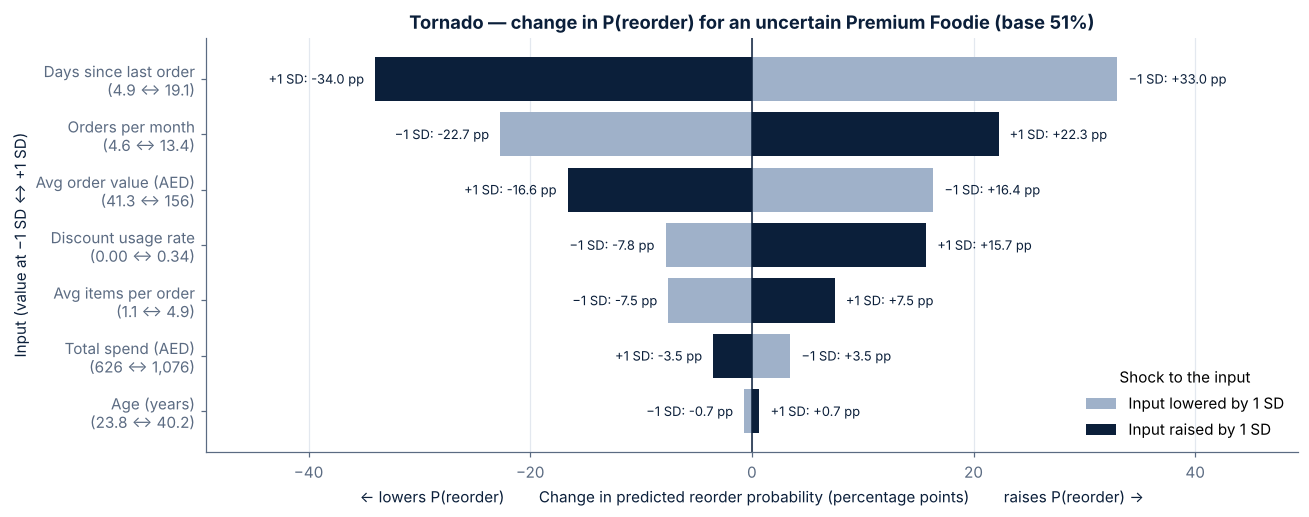

,feature,low_value,high_value,low_pp,high_pp,range_pp
5,age,23.810,40.190,-0.690,0.690,1.380
6,total_spend,626.300,"1,075.690",3.470,-3.480,6.950
2,avg_items_per_order,1.120,4.880,-7.530,7.480,15.010
4,discount_rate,0.000,0.340,-7.790,15.730,23.520
1,avg_order_value,41.340,155.620,16.380,-16.620,32.990
0,orders_per_month,4.580,13.420,-22.700,22.260,44.960
3,days_since_last_order,4.880,19.120,32.990,-33.990,66.980


In [50]:
coin = diners[(diners.segment == "Premium Foodies") & diners.reorder_prob_oof.between(0.4, 0.6)][CLASSIFICATION_FEATURES].median().to_dict()
_, p_base = score(coin)
sd = diners.loc[diners.include_in_classifier, CLASSIFICATION_FEATURES].std()
lo_obs = diners.loc[diners.include_in_classifier, CLASSIFICATION_FEATURES].min(); hi_obs = diners.loc[diners.include_in_classifier, CLASSIFICATION_FEATURES].max()
torn = []
for f in CLASSIFICATION_FEATURES:
    lo_p, hi_p = dict(coin), dict(coin)
    lo_p[f] = max(coin[f] - sd[f], lo_obs[f]); hi_p[f] = min(coin[f] + sd[f], hi_obs[f])
    torn.append({"feature": f, "low_value": lo_p[f], "high_value": hi_p[f],
                 "low_pp": (score(lo_p)[1] - p_base) * 100, "high_pp": (score(hi_p)[1] - p_base) * 100})
tornado = pd.DataFrame(torn)
tornado["range_pp"] = (tornado.high_pp - tornado.low_pp).abs()
tornado = tornado.sort_values("range_pp")
fig, ax = plt.subplots(figsize=(12, 4.8))
yl = [f"{LABELS[f]}\n({fmt_num(lv)} ↔ {fmt_num(hv)})" for f, lv, hv in zip(tornado.feature, tornado.low_value, tornado.high_value)]
# Neutral colours by shock (not red/green) so a negative shock that *raises* probability is not misread as bad news
b_lo = ax.barh(yl, tornado.low_pp, color="#9FB1C9", label="Input lowered by 1 SD")
b_hi = ax.barh(yl, tornado.high_pp, color=NAVY, label="Input raised by 1 SD")
for bars_, tag in ((b_lo, "−1 SD"), (b_hi, "+1 SD")):
    for b_ in bars_:
        w = b_.get_width()
        if abs(w) >= 0.05:
            ax.text(w + (1 if w >= 0 else -1), b_.get_y() + b_.get_height() / 2, f"{tag}: {w:+.1f} pp", va="center",
                    ha="left" if w >= 0 else "right", fontsize=8.5, color=NAVY)
ax.axvline(0, color=NAVY, lw=1)
lim = max(abs(tornado.low_pp).max(), abs(tornado.high_pp).max()) * 1.45; ax.set_xlim(-lim, lim)

ax.set(title=f"Tornado — change in P(reorder) for an uncertain Premium Foodie (base {p_base:.0%})",
       xlabel="← lowers P(reorder)        Change in predicted reorder probability (percentage points)        raises P(reorder) →",
       ylabel="Input (value at −1 SD ↔ +1 SD)")
ax.legend(title="Shock to the input", loc="lower right"); x_grid(ax)
savefig(fig, "tornado_sensitivity")
tornado.round(2)

## 13. Save the model artifact (`food_models.joblib`) — exact `app.py` contract

In [51]:
assert CLUSTER_FEATURES == ["orders_per_month", "avg_order_value", "avg_items_per_order", "days_since_last_order", "discount_rate"]
assert CLASSIFICATION_FEATURES == CLUSTER_FEATURES + ["age", "total_spend"]
assert list(cluster_scaler.feature_names_in_) == CLUSTER_FEATURES and cluster_scaler.n_features_in_ == 5
assert list(clf.feature_names_in_) == CLASSIFICATION_FEATURES and clf.n_features_in_ == 7
assert clf.named_steps["scaler"] is not cluster_scaler                        # independent preprocessing pipelines
assert set(segment_names) == set(range(K)) and all(s in reco for s in segment_names.values())

food_models = {
    "scaler": cluster_scaler,        # 5-feature StandardScaler used for clustering
    "kmeans": kmeans,                # K = 3
    "segment_names": segment_names,  # {cluster number: business name}
    "clf": clf,                      # Pipeline(StandardScaler → LogisticRegression) on 7 features
    "features": CLUSTER_FEATURES,    # clustering features, in contract order
    "reco": reco,                    # {segment name: most-ordered items}
}
joblib.dump(food_models, "food_models.joblib")
print("Saved food_models.joblib with keys:", list(food_models))

Saved food_models.joblib with keys: ['scaler', 'kmeans', 'segment_names', 'clf', 'features', 'reco']


In [52]:
# Separate analytics bundle for the enhanced dashboard (keeps food_models.joblib to the exact contract)
dist_to_centroid = np.linalg.norm(X_cluster - kmeans.cluster_centers_[kmeans.labels_], axis=1)
train_ranges = {c: (float(diners.loc[diners.include_in_classifier, c].min()), float(diners.loc[diners.include_in_classifier, c].max()))
                for c in CLASSIFICATION_FEATURES}
bundle = {
    "meta": {"trained_at": dt.datetime.now().strftime("%d %b %Y, %H:%M"), "sklearn": sklearn.__version__, "mlxtend": mlxtend.__version__,
             "seed": SEED, "K": K, "n_diners": len(diners), "n_model_rows": len(model_df), "n_train": len(X_train),
             "n_test": len(X_test), "n_baskets": n_baskets, "n_order_rows": len(orders), "n_items": orders.item.nunique(),
             "model_type": "Logistic Regression (StandardScaler → LogisticRegression, L2, C = 1.0)",
             "cluster_model": "K-Means (k = 3, n_init = 20) on StandardScaler-transformed features",
             "split": "80 / 20 stratified, random_state = 42", "target": "reordered (1 = ordered again, 0 = churned)",
             "dq_status": overall_status, "min_support_overall": MIN_SUPPORT_OVERALL, "min_support_segment": MIN_SUPPORT_SEGMENT,
             "strategic": STRATEGIC},
    "diners": diners, "seg_order": SEG_ORDER, "seg_colors": SEG_COLORS, "seg_profile": seg_profile, "seg_index": seg_index,
    "seg_strategy": SEGMENT_STRATEGY, "seg_econ": seg_econ, "segment_action": segment_action,
    "value_cut": VALUE_CUT, "risk_cut": RISK_CUT,
    "k_eval": k_eval, "pca_var": pca.explained_variance_ratio_.tolist(),
    "centroid_dist_p95": float(np.percentile(dist_to_centroid, 95)),
    "item_freq": item_freq, "share_mat": share_mat, "rules_all": rules_all.drop(columns="bundle"),
    "top_overall": top_overall.drop(columns="bundle"), "strategic_overall": strategic_overall.drop(columns="bundle"),
    "seg_rules": {s: best_per_bundle(r).drop(columns="bundle") for s, r in seg_rules.items()}, "seg_baskets": seg_baskets,
    "basket_opportunity": basket_opportunity,
    "metrics": metrics, "cm": cm, "roc": (fpr, tpr), "calibration": (mean_pred, frac_pos), "model_comparison": model_comparison,
    "importance": importance, "threshold_table": threshold_table, "risk_tiers": RISK_TIERS, "tier_summary": tier_summary,
    "scenarios": scenarios, "train_ranges": train_ranges,
    "validation": {"bootstrap_ci": bootstrap_ci, "repeated_cv": repeated_cv, "cv_scores": cv_scores,
                   "cluster_stability": cluster_stability, "ari_boot": ari_boot, "kw_tests": kw_tests, "chi2": chi2_test},
    "lorenz": {"pop": cum_pop[::4], "rev": cum_rev[::4], "gini": gini, "conc": conc, "top20_mix": top20_mix},
    "roi_defaults": ROI_DEFAULTS, "roi_curve": roi_curve, "tornado": tornado,
    "under18": {"n": int((diners.age < ADULT_AGE).sum()), "ages": diners.loc[diners.age < ADULT_AGE, "age"].value_counts().sort_index(),
                "segments": diners.loc[diners.age < ADULT_AGE, "segment"].value_counts().reindex(SEG_ORDER).fillna(0).astype(int),
                "reorder_rate": float(diners.loc[diners.age < ADULT_AGE, TARGET].mean()), "adult_age": ADULT_AGE},
    "dq": {"scorecard": scorecard, "issue_log": issue_log, "recon": recon, "outliers": outliers, "status": overall_status},
    "labels": LABELS,
}
def portable(obj):
    """Store DataFrames / Series / arrays as plain Python so the bundle loads across pandas & numpy versions."""
    if isinstance(obj, pd.DataFrame):
        return {"__df__": obj.to_dict(orient="split")}
    if isinstance(obj, pd.Series):
        return {"__series__": {"index": obj.index.tolist(), "data": obj.tolist(), "name": obj.name}}
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, dict):
        return {k: portable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return type(obj)(portable(v) for v in obj)
    return obj

joblib.dump(portable(bundle), "dashboard_bundle.joblib")
print("Saved dashboard_bundle.joblib")

Saved dashboard_bundle.joblib


## 14. Model-dashboard compatibility validation
Reload from disk and run the **exact** `analyse()` logic from the supplied `app.py` on a battery of diner profiles.

In [53]:
M = joblib.load("food_models.joblib")
assert set(M) == {"scaler", "kmeans", "segment_names", "clf", "features", "reco"}, "Missing / extra keys"
_scaler, _kmeans = M["scaler"], M["kmeans"]
_seg_names, _clf, _FEATURES, _reco = M["segment_names"], M["clf"], M["features"], M["reco"]

def analyse(profile: dict):            # verbatim logic from app.py
    row = pd.DataFrame([profile])
    seg = int(_kmeans.predict(_scaler.transform(row[_FEATURES]))[0])
    name = _seg_names.get(seg, f"Segment {seg}")
    reorder = int(_clf.predict(row[_FEATURES + ["age", "total_spend"]])[0])
    prob = float(_clf.predict_proba(row[_FEATURES + ["age", "total_spend"]])[0][1])
    return name, reorder, prob, _reco.get(name, [])

tests = {
    "Typical diner (app default)": dict(age=28, orders_per_month=8, avg_order_value=90, avg_items_per_order=3, days_since_last_order=10, discount_rate=0.3, total_spend=800),
    "Low-risk / high-frequency": dict(age=22, orders_per_month=15, avg_order_value=40, avg_items_per_order=2, days_since_last_order=2, discount_rate=0.65, total_spend=600),
    "Medium-risk premium": dict(age=33, orders_per_month=9, avg_order_value=100, avg_items_per_order=3, days_since_last_order=12, discount_rate=0.1, total_spend=900),
    "High-risk long recency": dict(age=42, orders_per_month=3, avg_order_value=180, avg_items_per_order=6, days_since_last_order=28, discount_rate=0.3, total_spend=540),
    "High-spend diner": dict(age=38, orders_per_month=12, avg_order_value=130, avg_items_per_order=4, days_since_last_order=8, discount_rate=0.05, total_spend=1500),
    "Low-frequency diner": dict(age=45, orders_per_month=1, avg_order_value=160, avg_items_per_order=6, days_since_last_order=20, discount_rate=0.2, total_spend=160),
    "Discount-heavy diner": dict(age=20, orders_per_month=12, avg_order_value=38, avg_items_per_order=2, days_since_last_order=6, discount_rate=0.9, total_spend=450),
    "Extreme slider corner (max all)": dict(age=70, orders_per_month=20, avg_order_value=250, avg_items_per_order=10, days_since_last_order=60, discount_rate=1.0, total_spend=20000),
    "Extreme slider corner (min all)": dict(age=18, orders_per_month=1, avg_order_value=15, avg_items_per_order=1, days_since_last_order=0, discount_rate=0.0, total_spend=50),
}
val_rows = []
for name, prof in tests.items():
    seg, reorder, prob, items = analyse(prof)
    assert seg in _seg_names.values() and reorder in (0, 1) and 0.0 <= prob <= 1.0 and len(items) > 0
    assert reorder == int(prob >= 0.5)
    val_rows.append({"Test profile": name, "Segment": seg, "Will reorder?": "Yes" if reorder else "At risk",
                     "P(reorder)": prob, "Risk tier": risk_tier(prob), "Recommended items": ", ".join(items)})
validation = pd.DataFrame(val_rows)
print("All", len(tests), "profiles passed the app.py inference pathway.")
validation

All 9 profiles passed the app.py inference pathway.


,Test profile,Segment,Will reorder?,P(reorder),Risk tier,Recommended items
0,Typical diner (app default),Premium Foodies,Yes,0.719,Moderate retention likelihood,"salad, sushi, coffee, wine"
1,Low-risk / high-frequency,Budget Students,Yes,0.997,High retention likelihood,"cola, fries, burger, wrap"
2,Medium-risk premium,Premium Foodies,At risk,0.493,At-risk,"salad, sushi, coffee, wine"
3,High-risk long recency,Family Feasters,At risk,0.010,High churn risk,"dessert, pizza, raita, biryani"
4,High-spend diner,Premium Foodies,Yes,0.699,Moderate retention likelihood,"salad, sushi, coffee, wine"
5,Low-frequency diner,Family Feasters,At risk,0.045,High churn risk,"dessert, pizza, raita, biryani"
6,Discount-heavy diner,Budget Students,Yes,0.994,High retention likelihood,"cola, fries, burger, wrap"
7,Extreme slider corner (max all),Family Feasters,At risk,0.000,High churn risk,"dessert, pizza, raita, biryani"
8,Extreme slider corner (min all),Premium Foodies,Yes,0.863,High retention likelihood,"salad, sushi, coffee, wine"


In [54]:
# In-sample sanity check: the reloaded models reproduce the in-notebook objects exactly
assert (M["kmeans"].predict(M["scaler"].transform(diners[CLUSTER_FEATURES])) == diners.cluster).all()
assert np.allclose(M["clf"].predict_proba(X_test)[:, 1], p_test)
print("Reloaded artifact reproduces notebook predictions exactly.")

Reloaded artifact reproduces notebook predictions exactly.


## 15. Business takeaway

In [55]:
prem_p, fam_p, stud_p = (seg_profile.loc[s] for s in SEG_ORDER)
top_prem_rule = basket_opportunity[basket_opportunity.Segment == "Premium Foodies"].iloc[0]
top_fam_rule = basket_opportunity[basket_opportunity.Segment == "Family Feasters"].iloc[0]
at_risk_n = int((model_df.reorder_prob_oof < 0.5).sum())
pe, fe = seg_econ.loc["Premium Foodies"], seg_econ.loc["Family Feasters"]
# Guard the narrative: fail loudly if the data no longer supports it
assert seg_econ.value.idxmax() == "Premium Foodies" and seg_econ.movable_value.idxmax() == "Premium Foodies"
assert seg_econ.churn.idxmax() == "Family Feasters"
takeaway = (
    f"**1. Prioritise Premium Foodies.** They are {prem_p['Share of diners']:.0%} of diners but {prem_p['Share of monthly revenue']:.0%} of estimated monthly revenue "
    f"(AED {prem_p['Est. monthly spend (AED)']:,.0f} per diner, the highest), yet only {prem_p['Reorder rate']:.0%} reorder. "
    f"{pe.movable_diners} of {pe.diners_n} sit in the uncertain 25–75% probability band, holding AED {pe.movable_value:,.0f} of monthly spend — "
    f"the value retention spend can most realistically move. Family Feasters churn most ({fam_p['Churn rate']:.0%}), but {fe.lapsed_diners} of {fe.diners_n} are already "
    f"below 25%, so they warrant a selective, low-cost win-back; Budget Students ({stud_p['Reorder rate']:.0%} reorder) should be served efficiently with less discounting. "
    f"**2. Promote segment-specific bundles:** {top_prem_rule['If basket has (A)']} → {top_prem_rule['Recommend (B)']} for Premium Foodies "
    f"({top_prem_rule['Confidence']:.0%} confidence, lift {top_prem_rule['Lift']:.1f}) and {top_fam_rule['If basket has (A)']} → {top_fam_rule['Recommend (B)']} "
    f"as a family 'pizza night' set ({top_fam_rule['Confidence']:.0%}, lift {top_fam_rule['Lift']:.1f}). "
    f"**3. Use the reorder model as a weekly risk ranking:** it is {repeated_cv['acc_mean']:.0%} accurate in repeated cross-validation "
    f"({metrics['Accuracy']:.0%} on the held-out test split) vs a {baseline_acc:.0%} majority baseline, with ROC-AUC {repeated_cv['auc_mean']:.2f}. "
    f"Score every adult diner weekly, rank the {at_risk_n} below 50% reorder probability by *expected value* of an offer (probability × spend × margin − cost) "
    f"rather than probability alone, and treat recency as the early-warning signal. "
    f"**4. Next step:** run an A/B test stratified by segment (randomised hold-out in each) of the premium-bundle and family win-back offers. "
    f"Its measured success rates replace the planning assumptions and decide how the retention budget is split between Premium Foodies and Family Feasters."
)
bundle["takeaway"] = takeaway
joblib.dump(portable(bundle), "dashboard_bundle.joblib")
from IPython.display import Markdown
Markdown(takeaway)

**1. Prioritise Premium Foodies.** They are 27% of diners but 36% of estimated monthly revenue (AED 872 per diner, the highest), yet only 52% reorder. 101 of 130 sit in the uncertain 25–75% probability band, holding AED 88,385 of monthly spend — the value retention spend can most realistically move. Family Feasters churn most (85%), but 119 of 150 are already below 25%, so they warrant a selective, low-cost win-back; Budget Students (98% reorder) should be served efficiently with less discounting. **2. Promote segment-specific bundles:** Miso Soup + Sushi → Green Tea for Premium Foodies (92% confidence, lift 3.9) and Cola + Dessert + Pizza → Garlic Bread as a family 'pizza night' set (95%, lift 4.8). **3. Use the reorder model as a weekly risk ranking:** it is 86% accurate in repeated cross-validation (90% on the held-out test split) vs a 59% majority baseline, with ROC-AUC 0.94. Score every adult diner weekly, rank the 205 below 50% reorder probability by *expected value* of an offer (probability × spend × margin − cost) rather than probability alone, and treat recency as the early-warning signal. **4. Next step:** run an A/B test stratified by segment (randomised hold-out in each) of the premium-bundle and family win-back offers. Its measured success rates replace the planning assumptions and decide how the retention budget is split between Premium Foodies and Family Feasters.